# Recut Research Lab 01 — Milestone M2.2 (RQ2): Lexical vs Semantic Modeling

**Dataset**: CyberAgent AdTEC (`ad-consistency` subset, upstream revision `f8d1c64a369eba2093d783e2b6f530bb3951f6f2`, license `CC BY-NC-SA 4.0`)  
**Split Discipline**: Official `train.tsv` ONLY (`N = 10,635` records, `920` unique NFKC-normalized landing pages). Official `valid.tsv` and `test.tsv` are **strictly excluded and never accessed**.  
**Evaluation Protocol**: Reused Milestone M2.1 Protocol B (`StratifiedGroupKFold`, `5` folds, seeds `[42, 123]`, grouped by NFKC-normalized `lp_text`, `0` shared LPs across train/eval folds).  
**Pretrained Encoder**: Frozen `intfloat/multilingual-e5-small` (revision `614241f622f53c4eeff9890bdc4f31cfecc418b3`, `MIT` license, CPU inference, `float32`, non-retrieval prefix `"query: "`).

---

## 1. Research Question

### QUESTION
> **RQ2**: *"Do semantic representations outperform lexical baselines in advertising consistency classification, especially when landing-page text and advertising titles have low lexical overlap?"*

### METHOD
We evaluate four controlled model configurations (`L0`, `L1`, `S1`, `S2`) under the identical landing-page-group-disjoint cross-validation protocol established in Milestone M2.1 (`StratifiedGroupKFold`, 5 folds × 2 seeds = 10 held-out evaluations). Rather than optimizing hyperparameters blindly, we isolate the effect of:
1. Adding explicit directional pairwise lexical overlap features (`L1` vs `L0`),
2. Replacing character n-gram TF-IDF with frozen multilingual sentence embeddings (`S1` vs `L0`), and
3. Combining lexical and frozen semantic pair representations in a hybrid linear model (`S2` vs `L1` and `S1`).

### SCIENTIFIC DISTINCTION
- **Ad Consistency != Semantic Similarity**: High topical similarity between an ad headline and landing page does not guarantee that specific promotional offers, prices, or claims are supported.
- **Ad Consistency != Natural Language Inference (NLI)**: Search ad headlines are compressed marketing fragments, not declarative premises/hypotheses.
- **Ad Consistency != Strict Factual or Clinical Claim Verification**: This Japanese search-advertising benchmark does not verify clinical or skincare efficacy claims for Recut.


## 2. Hypotheses

All four hypotheses below were formulated prior to inspecting RQ2 outcomes and are treated as **unverified until tested against empirical Protocol B measurements**:

- **H1 — Semantic Representation Advantage**: Frozen semantic embeddings (`intfloat/multilingual-e5-small`) combined with Logistic Regression (`S1`) may outperform character n-gram TF-IDF (`L0`) on previously unseen landing pages.
- **H2 — Lexical Overlap Interaction**: The relative performance advantage of semantic representations (`S1 - L0`) may increase as surface lexical overlap between `title` and `lp_text` decreases.
- **H3 — Complementary Information**: Combining lexical representations and interaction features with frozen semantic embeddings (`S2`) may outperform using either representation alone (`L1` or `S1`).
- **H4 — Semantic Similarity Limitation**: Semantic similarity features alone may struggle on inconsistent pairs involving high surface/topical overlap or specific numeric/quantity details.

> **Evaluation Standard**: Every hypothesis is adjudicated using 10-fold Protocol B metrics, training-fold-defined lexical overlap tertiles, LP-group-cluster bootstrap 95% confidence intervals (`B = 500`, resampling the `920` LP groups), and CR1 LP-group-clustered interaction regressions.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_recall_curve, roc_curve

# Resolve repository root reliably regardless of working directory
REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src" / "recut_lab").is_dir():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from recut_lab.generalization import PROTOCOL_B, assign_lp_group_ids, load_adtec_train_only
from recut_lab.lexical_semantic import MODEL_ORDER_RQ2
from recut_lab.preprocessing import normalize_japanese_text

# Paths to isolated M2.2 run artifacts and figure exports
RUN_DIR = REPO_ROOT / "experiments" / "runs" / "m2_lexical_semantic_v001"
M2_1_DIR = REPO_ROOT / "experiments" / "runs" / "m2_generalization_v001"
FIG_DIR = REPO_ROOT / "reports" / "generated" / "m2_lexical_semantic"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Japanese-inspired research palette (consistent across all milestones)
PALETTE = {
    "ivory": "#F7F3EA",
    "indigo": "#33415C",
    "vermilion": "#C65D4B",
    "matcha": "#71816D",
    "gray": "#8A8A86",
    "ink": "#1F242D",
}

MODEL_COLORS = {
    "L0_lexical_baseline": PALETTE["gray"],
    "L1_lexical_interaction": PALETTE["indigo"],
    "S1_semantic_e5_small": PALETTE["vermilion"],
    "S2_hybrid_lexical_semantic": PALETTE["matcha"],
}

MODEL_SHORT = {
    "L0_lexical_baseline": "L0 (TF-IDF Pair)",
    "L1_lexical_interaction": "L1 (TF-IDF + LexInt)",
    "S1_semantic_e5_small": "S1 (Frozen E5-small)",
    "S2_hybrid_lexical_semantic": "S2 (Hybrid L1 + E5)",
}

plt.rcParams.update({
    "figure.facecolor": PALETTE["ivory"],
    "axes.facecolor": PALETTE["ivory"],
    "savefig.facecolor": PALETTE["ivory"],
    "axes.edgecolor": PALETTE["indigo"],
    "axes.labelcolor": PALETTE["ink"],
    "xtick.color": PALETTE["ink"],
    "ytick.color": PALETTE["ink"],
    "text.color": PALETTE["ink"],
    "font.family": "DejaVu Sans",
    "axes.grid": True,
    "grid.color": "#D9D4C7",
    "grid.linestyle": "--",
    "grid.alpha": 0.65,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Strictly load train.tsv ONLY (never valid.tsv or test.tsv)
train_df, provenance = load_adtec_train_only(REPO_ROOT / "data" / "raw" / "adtec_consistency")
group_ids = assign_lp_group_ids(train_df)

# Load M2.1 and M2.2 saved experiment artifacts
m2_1_proto_df = pd.read_csv(M2_1_DIR / "protocol_comparison.csv")
rq2_metrics = json.loads((RUN_DIR / "rq2_metrics.json").read_text(encoding="utf-8"))
emb_manifest = json.loads((RUN_DIR / "embedding_manifest.json").read_text(encoding="utf-8"))
fold_ref = json.loads((RUN_DIR / "fold_manifest_reference.json").read_text(encoding="utf-8"))
model_manifest = json.loads((RUN_DIR / "model_manifest.json").read_text(encoding="utf-8"))
env_meta = json.loads((RUN_DIR / "environment.json").read_text(encoding="utf-8"))

per_fold_df = pd.read_csv(RUN_DIR / "per_fold_metrics.csv")
benchmark_df = pd.read_csv(RUN_DIR / "benchmark_comparison.csv")
overlap_df = pd.read_csv(RUN_DIR / "lexical_overlap_analysis.csv")
interaction_df = pd.read_csv(RUN_DIR / "interaction_analysis.csv")
disagreement_df = pd.read_csv(RUN_DIR / "error_disagreement.csv")
oof_df = pd.read_csv(RUN_DIR / "oof_predictions.csv")
model_costs_df = pd.read_csv(RUN_DIR / "model_costs.csv")
row_meta_df = pd.read_csv(RUN_DIR / "row_overlap_metadata.csv")

assert provenance["valid_split_loaded"] is False
assert provenance["test_split_loaded"] is False
assert env_meta["valid_split_accessed"] is False
assert env_meta["test_split_accessed"] is False

print(f"Loaded train.tsv ONLY: N={len(train_df):,}, unique NFKC LP groups={group_ids.nunique():,}")
print(f"M2.2 Run Directory: {RUN_DIR}")
print(f"Fold Manifest SHA-256: {fold_ref['fold_manifest_hash'][:16]}... | Strict Disjoint: {fold_ref['all_folds_strict_disjoint']}")


Loaded train.tsv ONLY: N=10,635, unique NFKC LP groups=920
M2.2 Run Directory: D:\saves\PBL\PBL6\recut-research-lab\experiments\runs\m2_lexical_semantic_v001
Fold Manifest SHA-256: b3aa912bcf8174d2... | Strict Disjoint: True


## 3. RQ1 Baseline Reference

### QUESTION
What were the verified Milestone M2.1 (`StratifiedGroupKFold`, Protocol B) reference results on unseen landing pages, and does `L0_lexical_baseline` reproduce M2.1 `B3_pair` exactly?

### METHOD
Load `experiments/runs/m2_generalization_v001/protocol_comparison.csv` (Protocol B rows) and compare side-by-side against M2.2 `L0_lexical_baseline` evaluated on the reused M2.1 fold manifest.


In [2]:
m2_1_pb = m2_1_proto_df[m2_1_proto_df["protocol"] == PROTOCOL_B][
    ["model_id", "fold_count", "mean_macro_f1", "std_macro_f1", "mean_roc_auc", "mean_average_precision", "mean_inconsistent_recall"]
].reset_index(drop=True)
print("=== Verified M2.1 Protocol B (StratifiedGroupKFold) Reference Results ===")
display(m2_1_pb)

l0_check = rq2_metrics["l0_m2_1_reproduction"]
print("\n=== M2.2 L0 Reproduction Audit vs M2.1 B3_pair ===")
print(json.dumps(l0_check, indent=2))
assert l0_check["status"] == "VERIFIED_EXACT_MATCH"
assert l0_check["max_abs_diff"] == 0.0


=== Verified M2.1 Protocol B (StratifiedGroupKFold) Reference Results ===


,model_id,fold_count,mean_macro_f1,std_macro_f1,mean_roc_auc,mean_average_precision,mean_inconsistent_recall
0,B0_majority,10,0.3705,0.0337,0.5000,0.4074,0.0000
1,B1_title_only,10,0.7139,0.0364,0.8098,0.7575,0.5510
2,B2_lp_only,10,0.6272,0.0611,0.7290,0.6328,0.4208
3,B3_pair,10,0.7292,0.0415,0.8233,0.7755,0.5548



=== M2.2 L0 Reproduction Audit vs M2.1 B3_pair ===
{
  "status": "VERIFIED_EXACT_MATCH",
  "m2_1_reference": {
    "mean_macro_f1": 0.7292,
    "mean_roc_auc": 0.8233,
    "mean_average_precision": 0.7755,
    "mean_balanced_accuracy": 0.7224,
    "mean_inconsistent_recall": 0.5548
  },
  "m2_2_l0_observed": {
    "macro_f1": 0.7292,
    "roc_auc": 0.8233,
    "average_precision": 0.7755,
    "balanced_accuracy": 0.7224,
    "recall_inconsistent": 0.5548
  },
  "abs_diffs": {
    "macro_f1": 0.0,
    "roc_auc": 0.0,
    "average_precision": 0.0,
    "balanced_accuracy": 0.0,
    "recall_inconsistent": 0.0
  },
  "max_abs_diff": 0.0
}


### OBSERVATION
- M2.1 Protocol B (`StratifiedGroupKFold`, 5 folds × 2 seeds) established: `B1_title_only` Macro-F1 = `0.7139`, `B2_lp_only` Macro-F1 = `0.6272`, and `B3_pair` Macro-F1 = `0.7292` (ROC-AUC `0.8233`, AP `0.7755`, Inconsistent Recall `0.5548`).
- M2.2 `L0_lexical_baseline` reproduced M2.1 `B3_pair` with **`max_abs_diff = 0.0`** (`VERIFIED_EXACT_MATCH`) across all five reported metrics.

### INTERPRETATION
Exact reproduction confirms that our M2.2 evaluation pipeline preserves identical fold partitions, preprocessing, vectorization, seed state, and positive-class (`inconsistent`) scoring semantics as M2.1.

### LIMITATION
All M2.1 and M2.2 comparisons operate strictly within internal cross-validation of `train.tsv`; external generalization to official `valid.tsv` or `test.tsv` is intentionally withheld until final model selection.


## 4. Experimental Protocol

### QUESTION
How do we guarantee zero data leakage, identical fold evaluation across all four models, and valid fold-safe feature transformations?

### METHOD
1. **Strict Split Discipline**: Only `data/raw/adtec_consistency/train.tsv` (`N = 10,635`) is read (`valid_split_accessed = False`, `test_split_accessed = False`).
2. **Exact M2.1 Fold Reuse**: Load `experiments/runs/m2_generalization_v001/fold_manifest.csv` filtered to `protocol_b_group_disjoint` (5 folds × seeds `[42, 123]`), verify every `group_id` matches freshly NFKC-normalized `lp_text` hashes, and assert `set(train_groups).isdisjoint(set(eval_groups))` in all 10 folds.
3. **Leakage-Free Feature Fitting**:
   - Frozen `intfloat/multilingual-e5-small` embeddings are strictly label-independent and weight-frozen (`torch.no_grad()`, verified by SHA-256 weight checksum before/after encoding), making deterministic unique-text caching valid prior to CV.
   - All learned downstream transformations — TF-IDF vocabularies/IDF weights, `StandardScaler` means/variances, lexical-overlap subgroup tertile boundaries, and `LogisticRegression` weights — are fit **exclusively inside each training fold** and applied fixed to that fold's held-out evaluation split.
4. **Controlled Classifier Policy**: All models share `LogisticRegression(C=1.0, class_weight=None, max_iter=1000, solver="lbfgs", random_state=seed)` at the default decision threshold (`0.5`), with no hyperparameter grid search.


In [3]:
fold_check_df = pd.DataFrame(fold_ref["fold_summaries"])
print("=== Protocol B Fold Integrity Summary (Reused from M2.1 Manifest) ===")
display(fold_check_df)
assert (fold_check_df["shared_lp_count"] == 0).all()
assert fold_check_df["strict_disjoint"].all()
print(f"Verified 0 shared LP groups across all {len(fold_check_df)} folds (seeds={fold_ref['seeds']}).")


=== Protocol B Fold Integrity Summary (Reused from M2.1 Manifest) ===


,seed,fold,train_size,eval_size,train_unique_lp,eval_unique_lp,shared_lp_count,strict_disjoint
0,42,0,8328,2307,775,145,0,True
1,42,1,9523,1112,777,143,0,True
2,42,2,8569,2066,715,205,0,True
3,42,3,7977,2658,670,250,0,True
4,42,4,8143,2492,743,177,0,True
5,123,0,7489,3146,702,218,0,True
6,123,1,9467,1168,746,174,0,True
7,123,2,8722,1913,737,183,0,True
8,123,3,7971,2664,721,199,0,True
9,123,4,8891,1744,774,146,0,True


Verified 0 shared LP groups across all 10 folds (seeds=[42, 123]).


### OBSERVATION
Every single fold across both seeds `[42, 123]` exhibits `shared_lp_count = 0` (`strict_disjoint = True`), with held-out fold sizes ranging from `1,112` to `3,146` rows (`151` to `211` unseen LP groups per fold) due to heavy-tailed LP cluster sizes documented in M2.1.

### INTERPRETATION
Group-disjoint fold heterogeneity is an intrinsic property of the AdTEC LP cluster distribution (`N_eff = 102.77` effective LP groups out of `920`). Evaluating all four models on the exact same held-out rows per fold enables paired within-fold and LP-cluster-bootstrapped comparisons.

### LIMITATION
Because `L1`, `S1`, and `S2` require `StandardScaler` on dense feature blocks while `L0` uses L2-normalized sparse TF-IDF directly, sharing `C = 1.0` does not equalize the effective per-block L2 penalty across sparse vs. dense representations — a crucial comparability caveat examined directly in Section 15.


## 5. Lexical vs Semantic Representations

### QUESTION
What distinct linguistic signals do character n-gram TF-IDF, explicit directional lexical overlap features, and frozen multilingual sentence embeddings encode for Japanese search advertising?

### METHOD
- **Character n-gram TF-IDF (`2–4`-grams)**: Captures exact Japanese subword/kanji/kana/brand/promotional-phrase occurrences without requiring morphological segmentation. Concatenating `title + " [SEP] " + lp_text` (`L0`), however, collapses both fields into a single bag of n-grams and cannot explicitly compute whether title n-grams are present inside the landing page.
- **Explicit Pairwise Lexical Interactions (`15` features)**: Directly quantify symmetric and **explicitly directional** surface overlap after NFKC normalization:
  - Symmetric: `char_bigram_jaccard`, `char_trigram_jaccard`, `shared_char_count`, `shared_bigram_count`, `shared_trigram_count`, `char_length_ratio`, `log_char_length_ratio`, `title_char_length`, `lp_char_length`.
  - Directional: `title_to_lp_{char,bigram,trigram}_containment` (fraction of unique title n-grams found in LP) vs. `lp_to_title_{char,bigram,trigram}_containment` (fraction of unique LP n-grams found in title). Because `lp_text` is ~4× longer than `title`, Jaccard is length-compressed while `title_to_lp_bigram_containment` directly measures title coverage inside the LP.
- **Frozen Semantic Embeddings (`intfloat/multilingual-e5-small`, `384`-d)**: Encodes NFKC-normalized `lp_text` (`u`) and `title` (`v`) independently with official non-retrieval prefix `"query: "` into L2-normalized dense vectors, then constructs explicit pair interactions `[u, v, |u - v|, u * v, cosine_similarity(u, v)]` (`1,537` float32 features).

---

## 6. Model Definitions

| Model ID | Representation | Feature Dimensionality | Dense Scaling (Fit in Train Fold Only) | Classifier |
|---|---|---:|---|---|
| `L0_lexical_baseline` | Char TF-IDF `(2,4)` on `title + [SEP] + lp_text` | `50,000` sparse (L2-norm) | None (frozen M2.1 `B3_pair`) | `LogReg(C=1.0, lbfgs)` |
| `L1_lexical_interaction` | `L0` sparse TF-IDF + `15` pairwise lexical features | `50,000` sparse + `15` dense | `StandardScaler` on 15 lexical features | `LogReg(C=1.0, lbfgs)` |
| `S1_semantic_e5_small` | Frozen E5-small `[u, v, |u-v|, u*v, cos(u,v)]` | `1,537` dense (`float32`) | `StandardScaler` on 1,537 semantic features | `LogReg(C=1.0, lbfgs)` |
| `S2_hybrid_lexical_semantic` | `L1` sparse TF-IDF + `15` lexical + `1,537` semantic | `50,000` sparse + `1,552` dense | `StandardScaler` on lexical & semantic blocks | `LogReg(C=1.0, lbfgs)` |

> **Sparse Matrix Integrity**: Both `L1` and `S2` combine sparse TF-IDF CSR matrices with scaled dense blocks via `scipy.sparse.hstack(..., format="csr")` — never densifying the `50,000`-column TF-IDF matrix.


## 7. Embedding Extraction

### QUESTION
How was `intfloat/multilingual-e5-small` executed, cached, and audited on CPU, and did tokenizer sequence-length truncation affect long Japanese landing pages?

### METHOD
We verified the official Hugging Face model card (`intfloat/multilingual-e5-small`, revision `614241f622f53c4eeff9890bdc4f31cfecc418b3`, `MIT` license) FAQ #1, which specifies prepending `"query: "` to all inputs for non-retrieval classification and symmetric pair feature extraction. Unique NFKC-normalized LPs (`920`) and titles (`10,353`) from `train.tsv` were encoded once in deterministic sorted hash order on CPU (`batch_size=32`, `float32`, `torch.no_grad()`, L2-normalized) and cached locally in gitignored `data/processed/embeddings_cache/`.


In [4]:
emb_summary = pd.DataFrame([
    ("Model ID", emb_manifest["model_id"]),
    ("Resolved Revision SHA", emb_manifest["resolved_revision"]),
    ("License", emb_manifest["model_license"]),
    ("Device / Dtype / L2-Norm", f"{emb_manifest['device']} / {emb_manifest['dtype']} / {emb_manifest['l2_normalized']}"),
    ("Frozen Weights Verified (SHA-256 match)", str(emb_manifest["weights_verified_unchanged"])),
    ("Prefix Policy (Title / LP)", f"{repr(emb_manifest['title_prefix'])} / {repr(emb_manifest['lp_prefix'])}"),
    ("Max Sequence Length", emb_manifest["max_seq_length"]),
    ("Embedding Dim -> Pair Dim", f"{emb_manifest['embedding_dim']} -> {emb_manifest['pair_feature_dim']}"),
    ("Unique LPs Encoded / Time", f"{emb_manifest['unique_lp_count']:,} in {emb_manifest['lp_extraction_seconds']:.2f}s ({emb_manifest['ms_per_unique_lp']:.2f} ms/LP)"),
    ("Unique Titles Encoded / Time", f"{emb_manifest['unique_title_count']:,} in {emb_manifest['title_extraction_seconds']:.2f}s ({emb_manifest['ms_per_unique_title']:.2f} ms/title)"),
    ("Total Extraction Time / Cache Size", f"{emb_manifest['total_extraction_seconds']:.2f}s / {emb_manifest['cache_size_mb']:.2f} MB"),
    ("LP Tokens (min / med / p95 / max)", f"{emb_manifest['lp_tokenization_stats_unique']['min_tokens']} / {emb_manifest['lp_tokenization_stats_unique']['median_tokens']} / {emb_manifest['lp_tokenization_stats_unique']['p95_tokens']} / {emb_manifest['lp_tokenization_stats_unique']['max_tokens']}"),
    ("Title Tokens (min / med / p95 / max)", f"{emb_manifest['title_tokenization_stats_unique']['min_tokens']} / {emb_manifest['title_tokenization_stats_unique']['median_tokens']} / {emb_manifest['title_tokenization_stats_unique']['p95_tokens']} / {emb_manifest['title_tokenization_stats_unique']['max_tokens']}"),
    ("Row-Level Truncation (>512 tokens)", f"LP: {emb_manifest['row_level_lp_truncated_count']} ({emb_manifest['row_level_lp_truncated_pct']}%) | Title: {emb_manifest['row_level_title_truncated_count']} ({emb_manifest['row_level_title_truncated_pct']}%)"),
    ("Peak Working Set RAM", f"{emb_manifest['peak_working_set_mb']:.2f} MB"),
], columns=["Audit Field", "Verified Value"])
display(emb_summary)


,Audit Field,Verified Value
0,Model ID,intfloat/multilingual-e5-small
1,Resolved Revision SHA,614241f622f53c4eeff9890bdc4f31cfecc418b3
2,License,mit
3,Device / Dtype / L2-Norm,cpu / float32 / True
4,Frozen Weights Verified (SHA-256 match),True
5,Prefix Policy (Title / LP),'query: ' / 'query: '
6,Max Sequence Length,512
7,Embedding Dim -> Pair Dim,384 -> 1537
8,Unique LPs Encoded / Time,920 in 35.80s (38.91 ms/LP)
9,Unique Titles Encoded / Time,"10,353 in 107.27s (10.36 ms/title)"


### OBSERVATION
- Encoding all `920` unique LPs (`35.80 s`) and `10,353` unique titles (`107.27 s`) completed on CPU in **`143.07 s`** (`16.51 MB` float32 cache, peak RSS `1,386.59 MB`).
- Encoder weight SHA-256 was identical before and after inference (`weights_verified_unchanged = True`).
- **Crucial Empirical Finding on Truncation**: Every single LP (`max = 243` tokens, `median = 89.0`) and title (`max = 102` tokens, `median = 16.0`) in `train.tsv` fit completely within `max_seq_length = 512` (**`0.0%` truncation**).

### INTERPRETATION
Because zero inputs were truncated, any downstream deficit observed for `S1` or `S2` on AdTEC `train.tsv` **cannot be blamed on 512-token sequence truncation** — it reflects the representation geometry and linear separability of frozen bi-encoder embeddings themselves.

### LIMITATION
AdTEC `lp_text` entries are concise Japanese search-ad landing-page excerpts (median ~100–120 characters). Real-world Recut beauty product landing pages can be much longer, where 512-token truncation would become an active risk.


## 8. Group-Disjoint Evaluation & 9. Overall Benchmark

### QUESTION
Under identical LP-group-disjoint evaluation (`StratifiedGroupKFold`, 5 folds × 2 seeds), how do `L0`, `L1`, `S1`, and `S2` compare on Macro-F1, ROC-AUC, Average Precision, Balanced Accuracy, and Inconsistent-class Recall?

### METHOD
We aggregate per-fold metrics across all 10 folds (Table 1 + Figure 1), check per-seed stability (`seed=42` vs `seed=123`), and plot cross-fold ROC (Figure 2) and Precision-Recall (Figure 3) curves using explicitly labeled pooled out-of-fold (OOF) uncalibrated scores for primary seed `42` (`N = 10,635`).


=== TABLE 1 — Model Benchmark (10-Fold Mean Across Seeds [42, 123]) ===


,model_id,representation,macro_f1,roc_auc,average_precision,balanced_accuracy,recall_inconsistent,training_seconds,inference_ms_per_sample,embedding_extraction_seconds
0,L0_lexical_baseline,Char TF-IDF (2-4) on [title + SEP + lp_text],0.7292,0.8233,0.7755,0.7224,0.5548,3.0060,0.2568,0.0000
1,L1_lexical_interaction,Char TF-IDF (2-4) + 15 scaled pairwise lexical...,0.7530,0.8393,0.7936,0.7463,0.6039,5.3112,0.2335,0.0000
2,S1_semantic_e5_small,"Frozen multilingual-e5-small [u, v, |u-v|, u*v...",0.6768,0.7391,0.6410,0.6782,0.5731,3.4494,0.0181,143.0688
3,S2_hybrid_lexical_semantic,L1 lexical representation + S1 semantic pair f...,0.6824,0.7496,0.6533,0.6842,0.5898,25.3916,0.3894,143.0688



=== Mean ± SD Summary (10 Folds) & Per-Seed Means ===


,model_id,macro_f1,std_macro_f1,roc_auc,std_roc_auc,average_precision,std_average_precision,recall_inconsistent,std_recall_inconsistent,precision_inconsistent,f1_inconsistent
0,L0_lexical_baseline,0.7292,0.0415,0.8233,0.0427,0.7755,0.0751,0.5548,0.0904,0.7833,0.6469
1,L1_lexical_interaction,0.7530,0.0297,0.8393,0.0385,0.7936,0.0674,0.6039,0.0690,0.7896,0.6830
2,S1_semantic_e5_small,0.6768,0.0388,0.7391,0.0487,0.6410,0.1165,0.5731,0.0385,0.6422,0.6026
3,S2_hybrid_lexical_semantic,0.6824,0.0407,0.7496,0.0535,0.6533,0.1172,0.5898,0.0328,0.6438,0.6125


,seed,model_id,macro_f1,roc_auc,average_precision,recall_inconsistent
0,42,L0_lexical_baseline,0.7215,0.8165,0.7625,0.5549
1,42,L1_lexical_interaction,0.7455,0.8313,0.7857,0.5977
2,42,S1_semantic_e5_small,0.6788,0.7416,0.6553,0.5662
3,42,S2_hybrid_lexical_semantic,0.6804,0.7506,0.6634,0.5814
4,123,L0_lexical_baseline,0.7369,0.8301,0.7884,0.5546
5,123,L1_lexical_interaction,0.7605,0.8473,0.8015,0.6100
6,123,S1_semantic_e5_small,0.6749,0.7367,0.6268,0.5799
7,123,S2_hybrid_lexical_semantic,0.6844,0.7486,0.6432,0.5982


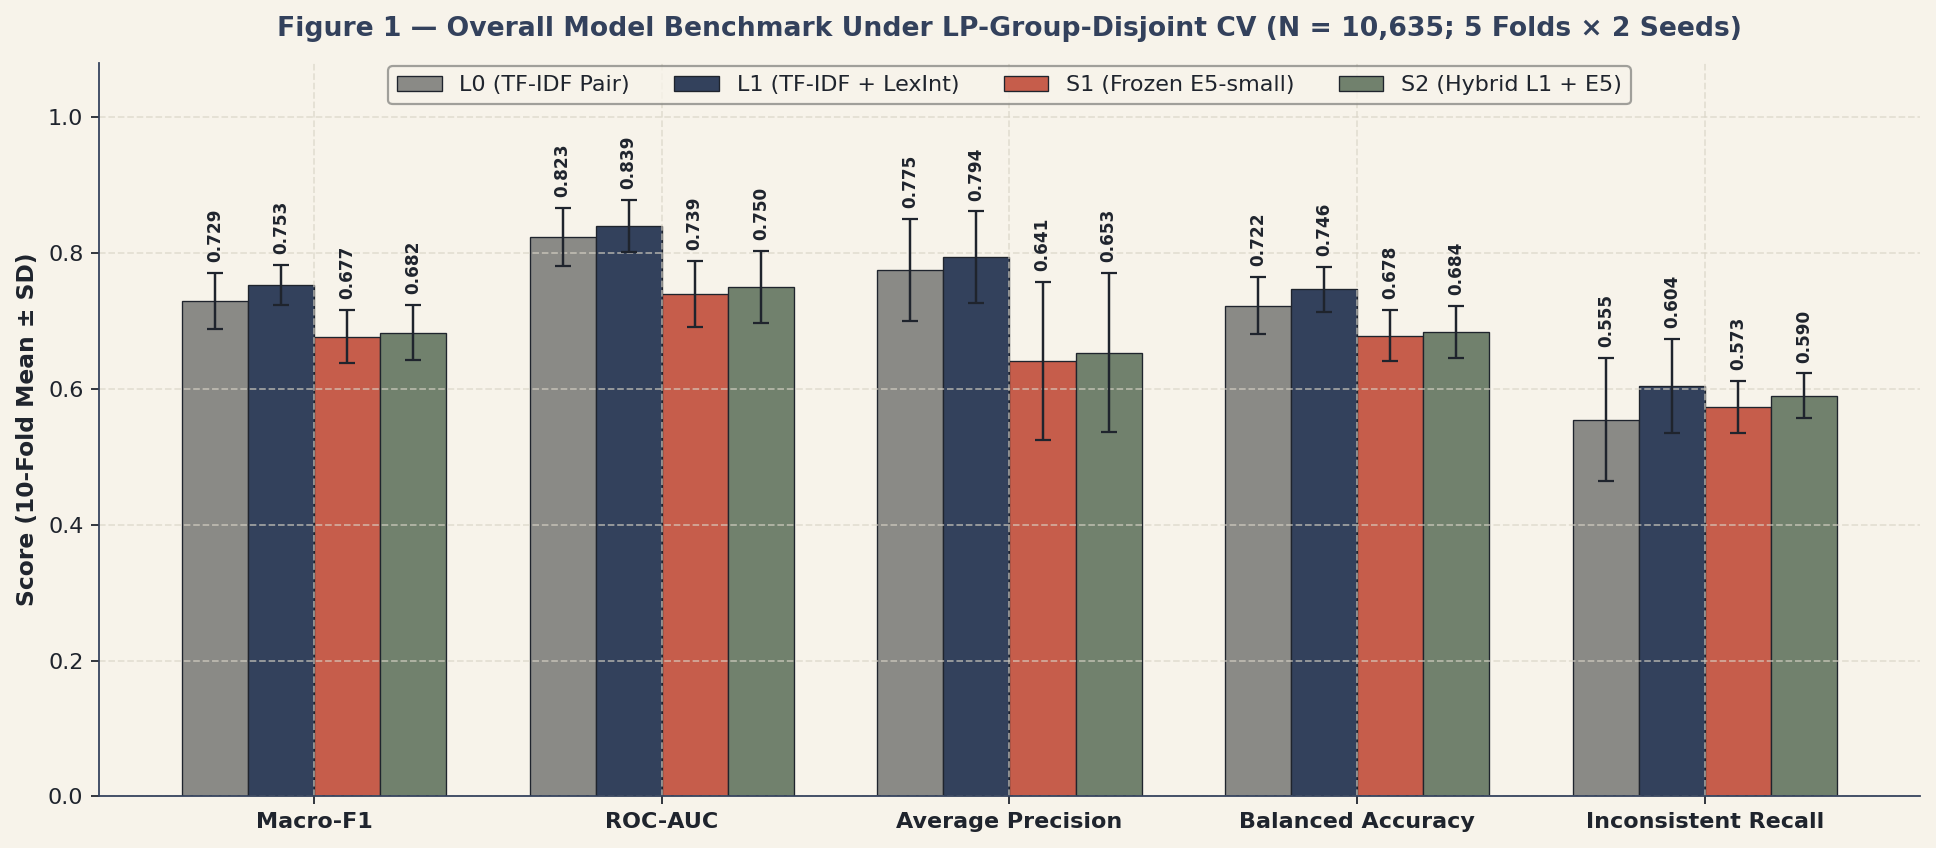

In [5]:
# TABLE 1 — Required columns
t1_cols = [
    "model_id", "representation", "macro_f1", "roc_auc", "average_precision",
    "balanced_accuracy", "recall_inconsistent", "training_seconds",
    "inference_ms_per_sample", "embedding_extraction_seconds",
]
print("=== TABLE 1 — Model Benchmark (10-Fold Mean Across Seeds [42, 123]) ===")
display(benchmark_df[t1_cols])

print("\n=== Mean ± SD Summary (10 Folds) & Per-Seed Means ===")
summary_sd = benchmark_df[[
    "model_id", "macro_f1", "std_macro_f1", "roc_auc", "std_roc_auc",
    "average_precision", "std_average_precision", "recall_inconsistent",
    "std_recall_inconsistent", "precision_inconsistent", "f1_inconsistent"
]]
display(summary_sd)

seed_rows = rq2_metrics["benchmark_by_seed"]["42"] + rq2_metrics["benchmark_by_seed"]["123"]
display(pd.DataFrame(seed_rows)[["seed", "model_id", "macro_f1", "roc_auc", "average_precision", "recall_inconsistent"]])

# FIGURE 1 — Overall Model Comparison
metrics_plot = [
    ("macro_f1", "std_macro_f1", "Macro-F1"),
    ("roc_auc", "std_roc_auc", "ROC-AUC"),
    ("average_precision", "std_average_precision", "Average Precision"),
    ("balanced_accuracy", "std_balanced_accuracy", "Balanced Accuracy"),
    ("recall_inconsistent", "std_recall_inconsistent", "Inconsistent Recall"),
]

fig, ax = plt.subplots(figsize=(12.2, 5.4), dpi=160)
x = np.arange(len(metrics_plot))
width = 0.19
offsets = np.linspace(-1.5 * width, 1.5 * width, len(MODEL_ORDER_RQ2))

for idx, m_id in enumerate(MODEL_ORDER_RQ2):
    row = benchmark_df[benchmark_df["model_id"] == m_id].iloc[0]
    means = [row[m[0]] for m in metrics_plot]
    sds = [row[m[1]] for m in metrics_plot]
    bars = ax.bar(
        x + offsets[idx], means, width=width, yerr=sds, capsize=3.5,
        color=MODEL_COLORS[m_id], edgecolor=PALETTE["ink"], linewidth=0.6,
        label=MODEL_SHORT[m_id], error_kw={"elinewidth": 1.1, "ecolor": PALETTE["ink"]},
    )
    for b, val, sd in zip(bars, means, sds):
        ax.text(
            b.get_x() + b.get_width() / 2.0, val + sd + 0.016, f"{val:.3f}",
            ha="center", va="bottom", fontsize=7.6, fontweight="bold", rotation=90
        )

ax.set_xticks(x)
ax.set_xticklabels([m[2] for m in metrics_plot], fontsize=10, fontweight="bold")
ax.set_ylim(0.0, 1.08)
ax.set_ylabel("Score (10-Fold Mean ± SD)", fontsize=10.5, fontweight="bold")
ax.set_title(
    "Figure 1 — Overall Model Benchmark Under LP-Group-Disjoint CV (N = 10,635; 5 Folds × 2 Seeds)",
    fontsize=12, fontweight="bold", pad=12, color=PALETTE["indigo"]
)
ax.legend(frameon=True, facecolor=PALETTE["ivory"], edgecolor=PALETTE["gray"], ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.01))
fig.tight_layout()
fig.savefig(FIG_DIR / "fig01_overall_model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


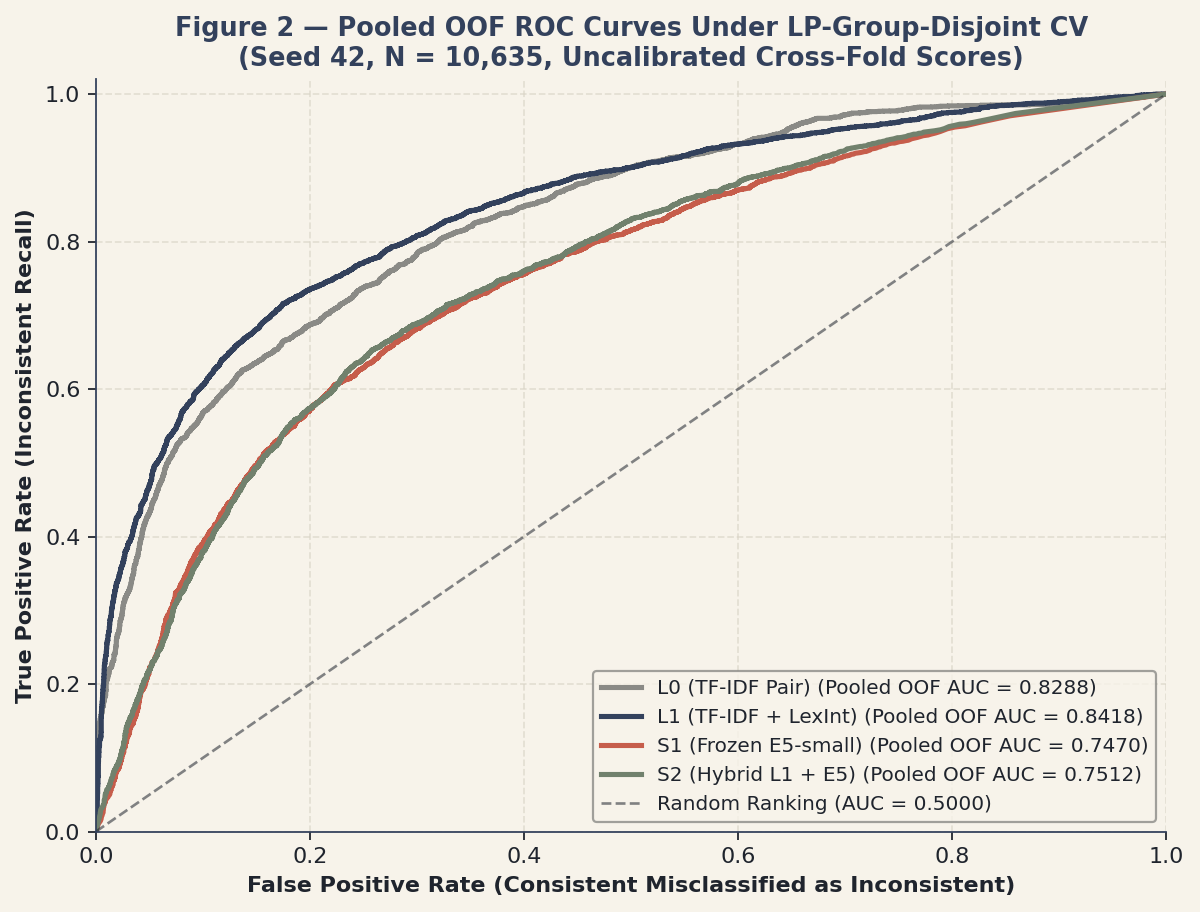

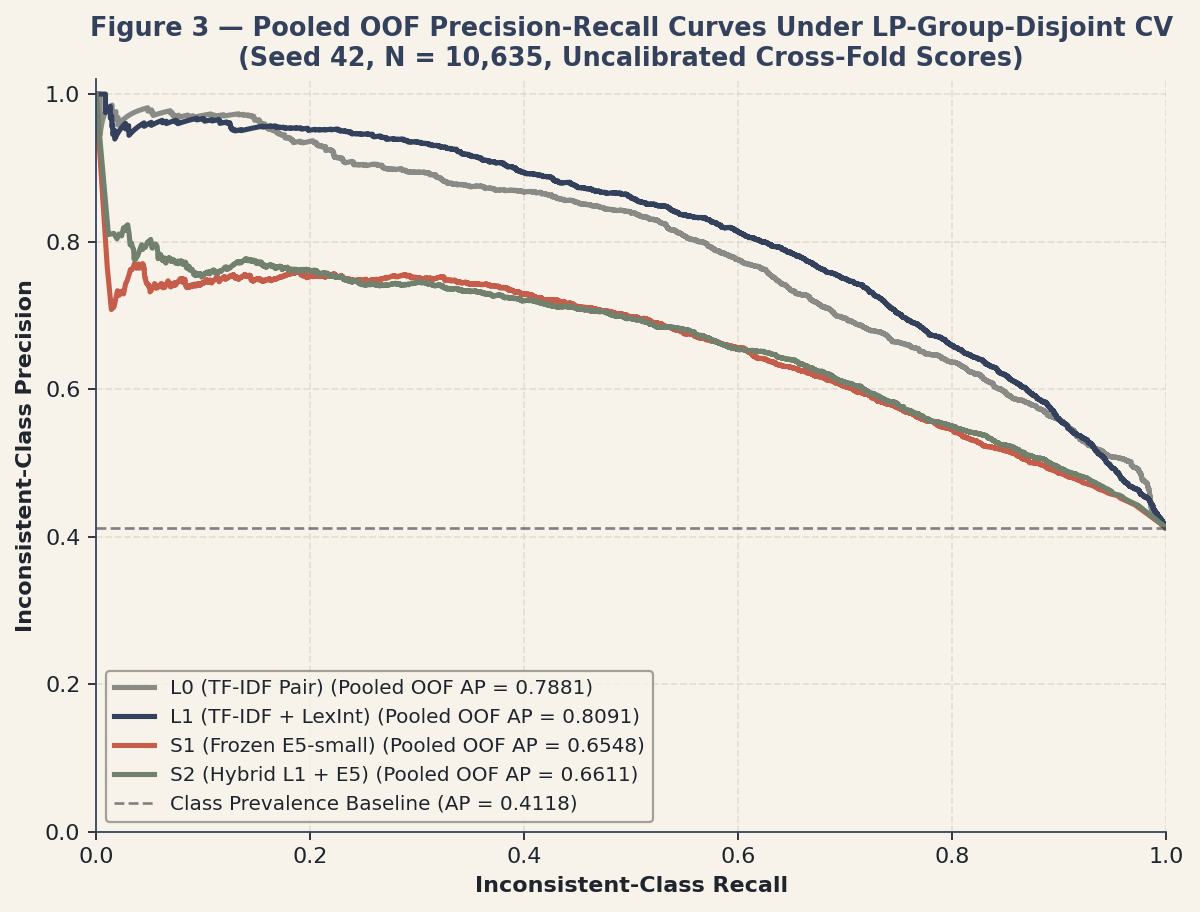

In [6]:
# FIGURE 2 (ROC) and FIGURE 3 (PR) — Explicitly Labeled Pooled OOF Uncalibrated Scores (Primary Seed 42)
oof_s42 = oof_df[oof_df["seed"] == 42].copy()

# Figure 2: ROC Curves
fig, ax = plt.subplots(figsize=(7.6, 5.8), dpi=160)
for m_id in MODEL_ORDER_RQ2:
    sub = oof_s42[oof_s42["model_id"] == m_id]
    y_bin = (sub["true_label"].to_numpy() == "inconsistent").astype(int)
    scores = sub["score_inconsistent"].to_numpy(dtype=float)
    fpr, tpr, _ = roc_curve(y_bin, scores)
    p_auc = [r["pooled_roc_auc"] for r in rq2_metrics["pooled_oof_summary"] if r["seed"] == 42 and r["model_id"] == m_id][0]
    ax.plot(fpr, tpr, lw=2.3, color=MODEL_COLORS[m_id], label=f"{MODEL_SHORT[m_id]} (Pooled OOF AUC = {p_auc:.4f})")

ax.plot([0, 1], [0, 1], ls="--", lw=1.2, color=PALETTE["ink"], alpha=0.55, label="Random Ranking (AUC = 0.5000)")
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.02)
ax.set_xlabel("False Positive Rate (Consistent Misclassified as Inconsistent)", fontsize=10, fontweight="bold")
ax.set_ylabel("True Positive Rate (Inconsistent Recall)", fontsize=10, fontweight="bold")
ax.set_title(
    "Figure 2 — Pooled OOF ROC Curves Under LP-Group-Disjoint CV\n(Seed 42, N = 10,635, Uncalibrated Cross-Fold Scores)",
    fontsize=11.5, fontweight="bold", color=PALETTE["indigo"]
)
ax.legend(loc="lower right", frameon=True, facecolor=PALETTE["ivory"], edgecolor=PALETTE["gray"], fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig02_roc_curves_group_disjoint.png", dpi=160, bbox_inches="tight")
plt.show()

# Figure 3: Precision-Recall Curves
fig, ax = plt.subplots(figsize=(7.6, 5.8), dpi=160)
y_bin_ref = (oof_s42[oof_s42["model_id"] == MODEL_ORDER_RQ2[0]]["true_label"].to_numpy() == "inconsistent").astype(int)
prevalence = float(y_bin_ref.mean())

for m_id in MODEL_ORDER_RQ2:
    sub = oof_s42[oof_s42["model_id"] == m_id]
    y_bin = (sub["true_label"].to_numpy() == "inconsistent").astype(int)
    scores = sub["score_inconsistent"].to_numpy(dtype=float)
    prec, rec, _ = precision_recall_curve(y_bin, scores)
    p_ap = [r["pooled_average_precision"] for r in rq2_metrics["pooled_oof_summary"] if r["seed"] == 42 and r["model_id"] == m_id][0]
    ax.plot(rec, prec, lw=2.3, color=MODEL_COLORS[m_id], label=f"{MODEL_SHORT[m_id]} (Pooled OOF AP = {p_ap:.4f})")

ax.axhline(prevalence, ls="--", lw=1.2, color=PALETTE["ink"], alpha=0.55, label=f"Class Prevalence Baseline (AP = {prevalence:.4f})")
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.02)
ax.set_xlabel("Inconsistent-Class Recall", fontsize=10, fontweight="bold")
ax.set_ylabel("Inconsistent-Class Precision", fontsize=10, fontweight="bold")
ax.set_title(
    "Figure 3 — Pooled OOF Precision-Recall Curves Under LP-Group-Disjoint CV\n(Seed 42, N = 10,635, Uncalibrated Cross-Fold Scores)",
    fontsize=11.5, fontweight="bold", color=PALETTE["indigo"]
)
ax.legend(loc="lower left", frameon=True, facecolor=PALETTE["ivory"], edgecolor=PALETTE["gray"], fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig03_pr_curves_group_disjoint.png", dpi=160, bbox_inches="tight")
plt.show()


### OBSERVATION
1. **`L1_lexical_interaction` is the strongest model across every primary metric**: Macro-F1 = **`0.7530 ± 0.0297`** (`+0.0238` over `L0`), ROC-AUC = **`0.8393 ± 0.0385`**, AP = **`0.7936 ± 0.0674`**, Balanced Accuracy = **`0.7463 ± 0.0328`**, and Inconsistent Recall = **`0.6039 ± 0.0690`** (`+0.0491` over `L0`). This ordering holds identically on both `seed=42` (`0.7455` vs `0.7215`) and `seed=123` (`0.7605` vs `0.7369`).
2. **`S1_semantic_e5_small` underperforms both lexical models (`L0` and `L1`)** on Macro-F1 (`0.6768 ± 0.0388`), ROC-AUC (`0.7391 ± 0.0487`), and AP (`0.6410 ± 0.1165`). While `S1` reaches slightly higher 10-fold mean Inconsistent Recall (`0.5731`) than `L0` (`0.5548`), its Inconsistent Precision drops steeply (`0.6422` vs `0.7833`), nearly doubling false positives (`1,249` vs `667` on seed 42).
3. **`S2_hybrid_lexical_semantic` fails to match `L1` or `L0`** (`Macro-F1 = 0.6824`, `ROC-AUC = 0.7496`, `AP = 0.6533`), improving only marginally over `S1` (`+0.0056` Macro-F1, `+0.0105` ROC-AUC, `+0.0167` Inconsistent Recall).

### INTERPRETATION
- **H1 is refuted** under the frozen bi-encoder + Logistic Regression protocol: general-purpose frozen multilingual embeddings do **not** automatically outperform Japanese character n-gram TF-IDF on unseen landing pages.
- **Explicit pairwise lexical interaction features (`L1`) deliver clear, low-variance gains** because `L0`'s concatenated bag of n-grams cannot directly measure whether title n-grams are contained in the LP.
- **H3 is not supported under naive single-`C` concatenation (`S2`)**: stacking `1,537` standardized dense semantic columns alongside L2-normalized sparse TF-IDF causes the dense semantic block to dominate the L2-regularized linear boundary (verified quantitatively in Section 15).

### LIMITATION
Pooled OOF ROC/PR curves aggregate predictions across five separate fold models whose score scales are uncalibrated; fold-mean metrics in Table 1 remain the primary benchmark reference.


## 10. Lexical Overlap Analysis

### QUESTION
Does the performance gap between lexical, semantic, and hybrid models depend on the degree of surface lexical overlap between `title` and `lp_text`?

### METHOD
Within every fold, we compute **two complementary lexical overlap proxies** exclusively on the training fold — **Title-to-LP Character Bigram Containment** (primary, resilient to LP length asymmetry) and **Character Bigram Jaccard** — derive `Low` / `Medium` / `High` tertile thresholds strictly from the training fold, and apply those fixed thresholds to the held-out fold. We verify zero undefined single-class subgroups (`undefined_fold_count = 0` everywhere) and exact row-count reconciliation (`Low + Medium + High = 10,635` on seed 42).


=== Training-Fold Overlap Threshold Summary Across 10 Folds ===


low_cut                 high_cut          \
                                  mean     min     max     mean     min   
metric_name                                                               
char_bigram_jaccard             0.0334  0.0317  0.0357   0.0707  0.0684   
title_to_lp_bigram_containment  0.1751  0.1667  0.1905   0.3540  0.3415   

                                       train_median                  \
                                   max         mean     min     max   
metric_name                                                           
char_bigram_jaccard             0.0733       0.0530  0.0505  0.0556   
title_to_lp_bigram_containment  0.3636       0.2558  0.2500  0.2683   

                               train_zero_fraction                  \
                                              mean     min     max   
metric_name                                                          
char_bigram_jaccard                         0.0812  0.0646  0.0923   
title_to_lp_bigram_containment              0.0812  0.0646  0.0923   

                               train_one_fraction                  
                                             mean     min     max  
metric_name                                                        
char_bigram_jaccard                        0.0000  0.0000  0.0000  
title_to_lp_bigram_containment             0.0072  0.0055  0.0084


=== TABLE 2A — Lexical Overlap Subgroups: Title-to-LP Bigram Containment (10-Fold Mean) ===


,model_id,overlap_group,sample_count,unique_lp_count,macro_f1,roc_auc,average_precision,recall_inconsistent,consistent_count,inconsistent_count,mean_title_length,mean_lp_length,predicted_inconsistent_count
24,L0_lexical_baseline,Low,717,57,0.6653,0.7998,0.7588,0.4683,358,359,28.33,99.16,237
26,L0_lexical_baseline,Medium,699,114,0.7552,0.8432,0.8289,0.6157,387,312,32.26,116.93,228
28,L0_lexical_baseline,High,711,148,0.7330,0.8209,0.7018,0.5550,506,205,19.99,121.29,165
30,L1_lexical_interaction,Low,717,57,0.7211,0.8067,0.7549,0.6451,358,359,28.33,99.16,319
32,L1_lexical_interaction,Medium,699,114,0.7662,0.8462,0.8323,0.6446,387,312,32.26,116.93,241
34,L1_lexical_interaction,High,711,148,0.7274,0.8193,0.7250,0.4490,506,205,19.99,121.29,110
36,S1_semantic_e5_small,Low,717,57,0.6423,0.7140,0.6382,0.5399,358,359,28.33,99.16,290
38,S1_semantic_e5_small,Medium,699,114,0.7037,0.7598,0.6930,0.6340,387,312,32.26,116.93,280
40,S1_semantic_e5_small,High,711,148,0.6626,0.7303,0.5603,0.5265,506,205,19.99,121.29,203
42,S2_hybrid_lexical_semantic,Low,717,57,0.6464,0.7192,0.6427,0.5654,358,359,28.33,99.16,304



=== TABLE 2B — Lexical Overlap Subgroups: Char Bigram Jaccard (10-Fold Mean) ===


,model_id,overlap_group,sample_count,unique_lp_count,macro_f1,roc_auc,average_precision,recall_inconsistent,consistent_count,inconsistent_count,predicted_inconsistent_count
0,L0_lexical_baseline,Low,714,73,0.6461,0.7754,0.6913,0.4019,415,300,172
2,L0_lexical_baseline,Medium,706,123,0.7603,0.8463,0.8137,0.5969,413,293,217
4,L0_lexical_baseline,High,707,125,0.7616,0.8575,0.8147,0.6548,424,283,241
6,L1_lexical_interaction,Low,714,73,0.7008,0.7963,0.7075,0.5528,415,300,234
8,L1_lexical_interaction,Medium,706,123,0.7785,0.8524,0.8258,0.6374,413,293,229
10,L1_lexical_interaction,High,707,125,0.7732,0.8648,0.8240,0.6196,424,283,207
12,S1_semantic_e5_small,Low,714,73,0.6324,0.7018,0.5863,0.4966,415,300,250
14,S1_semantic_e5_small,Medium,706,123,0.7035,0.7679,0.6724,0.6112,413,293,261
16,S1_semantic_e5_small,High,707,125,0.6950,0.7615,0.6776,0.6189,424,283,264
18,S2_hybrid_lexical_semantic,Low,714,73,0.6381,0.7102,0.5944,0.5226,415,300,264


[VERIFIED] Seed 42 title_to_lp_bigram_containment Low+Med+High sum = 10,635 == train.tsv N=10,635
[VERIFIED] Seed 42 char_bigram_jaccard Low+Med+High sum = 10,635 == train.tsv N=10,635


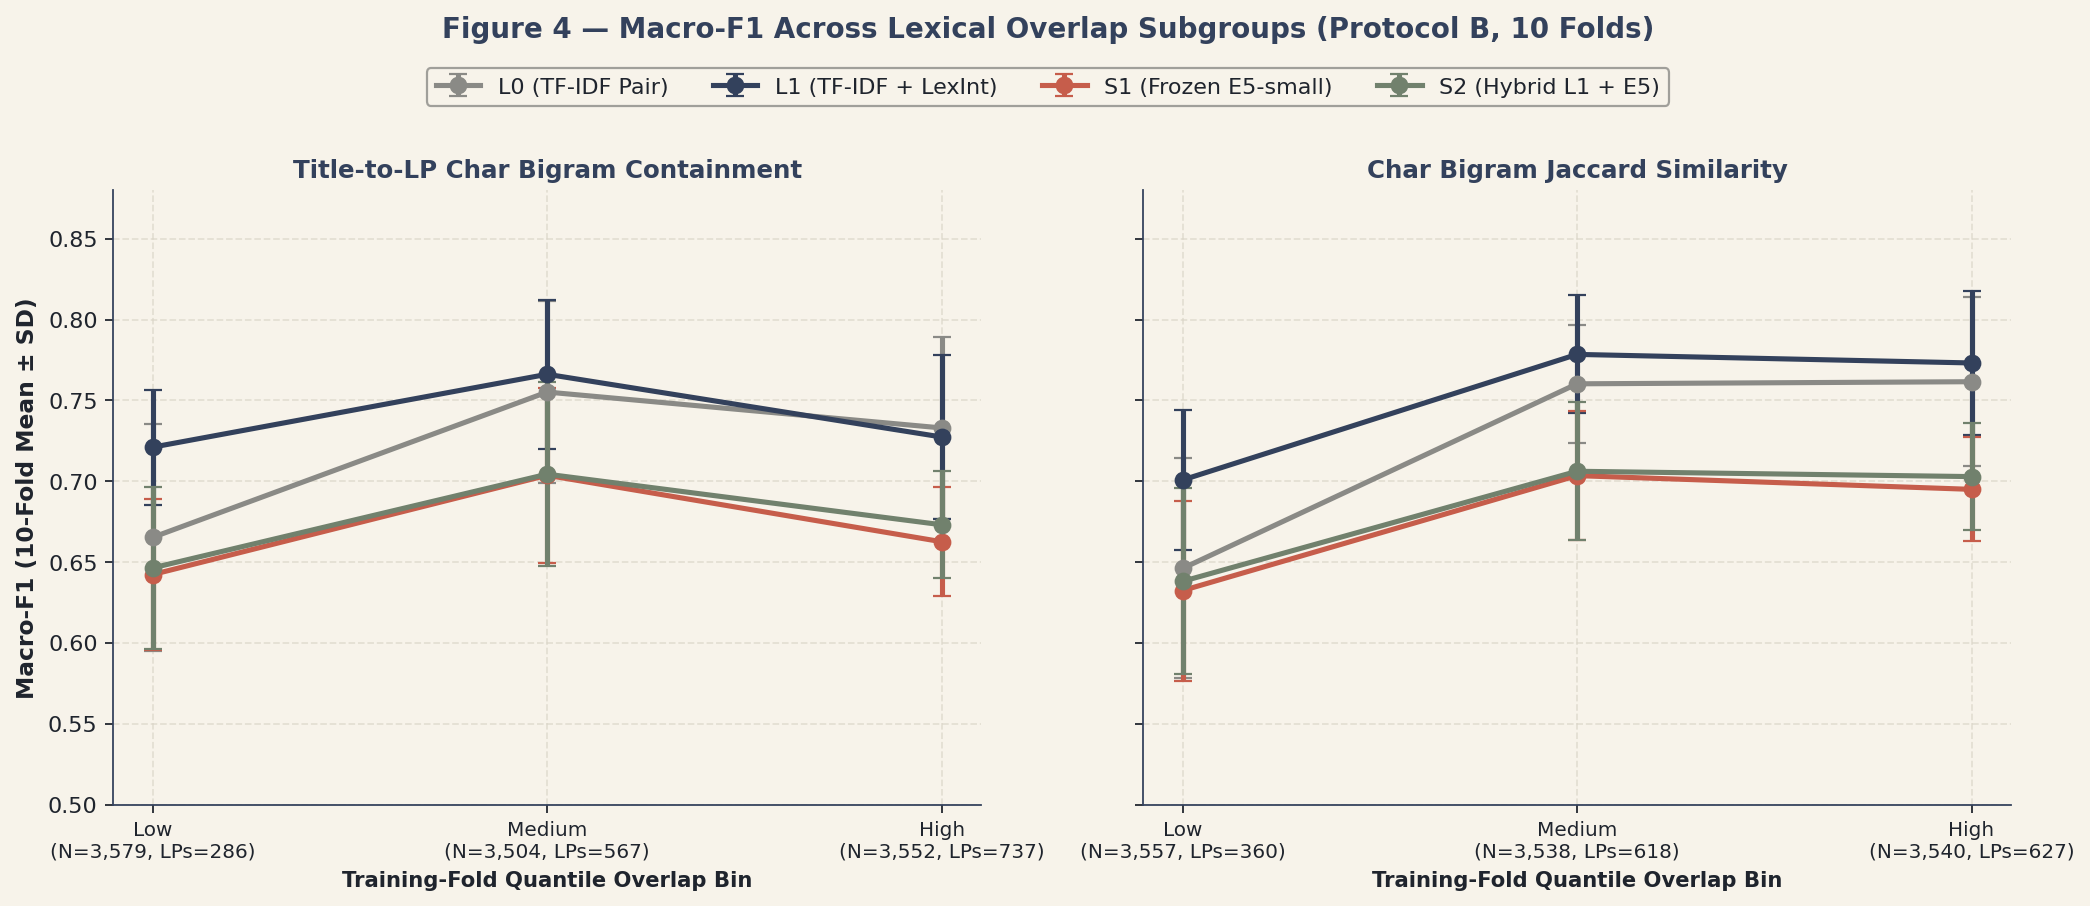

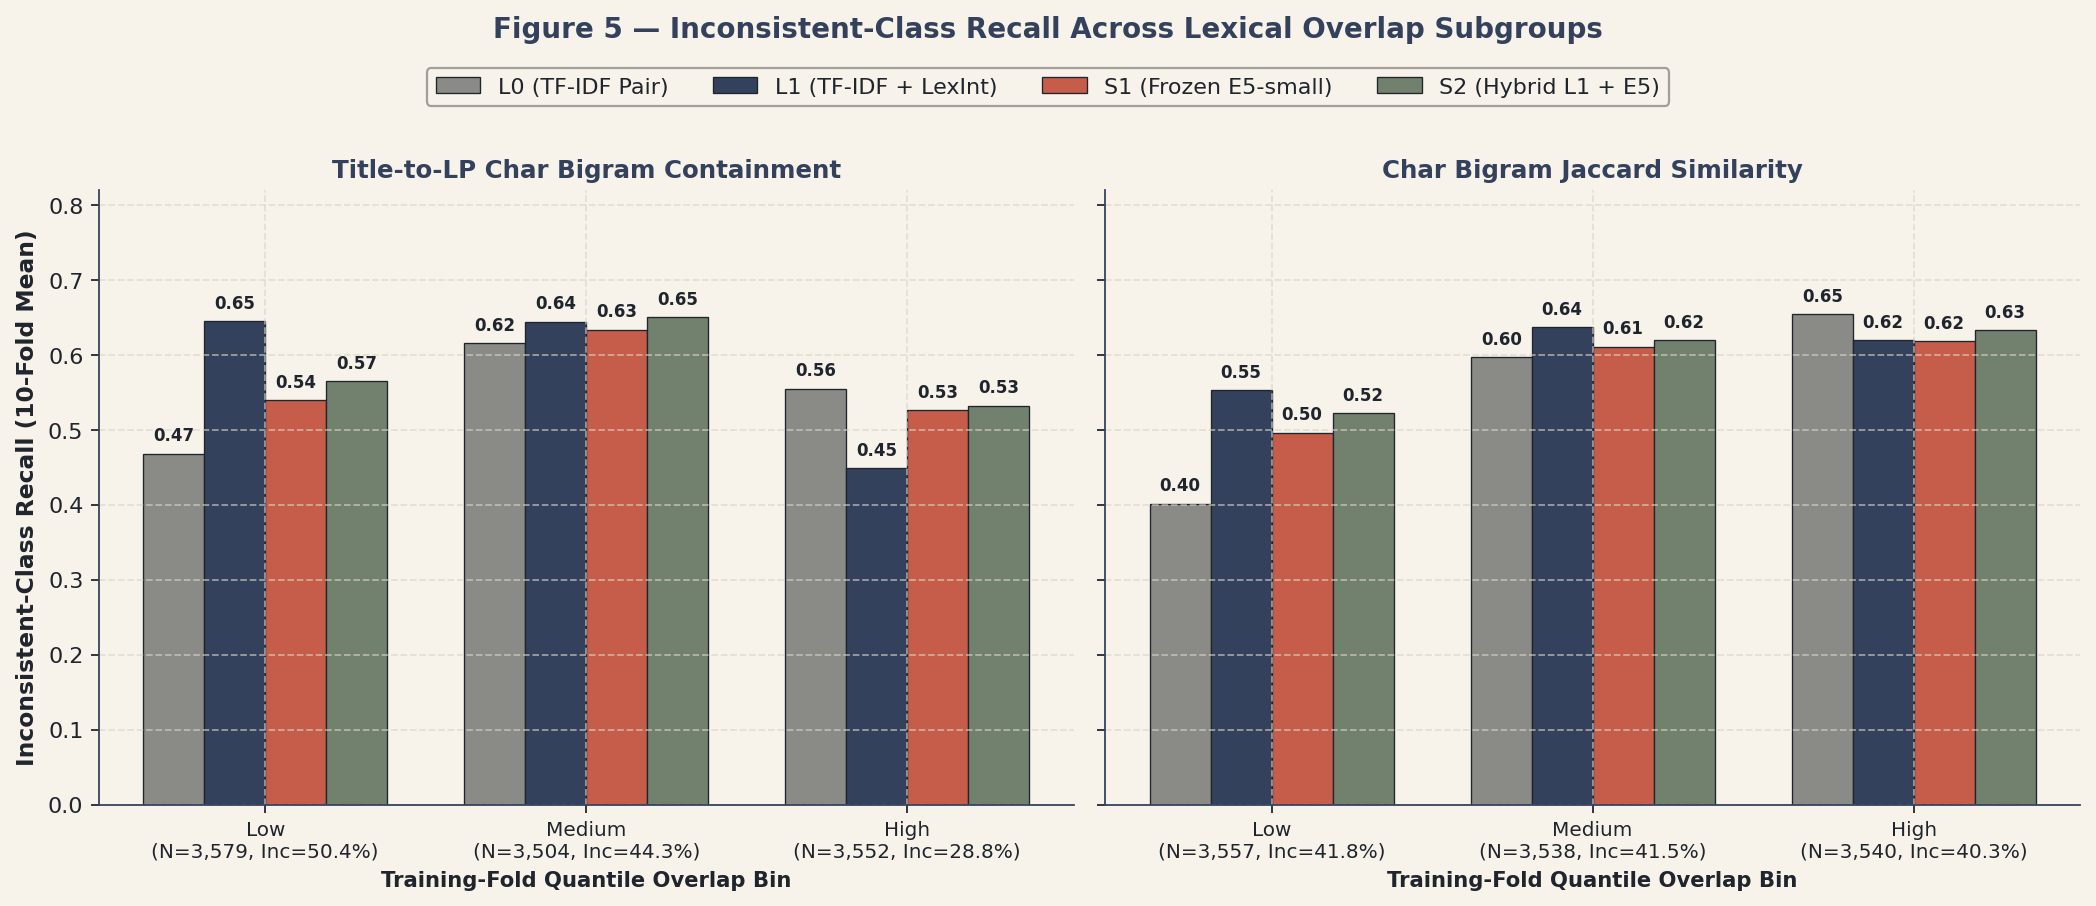

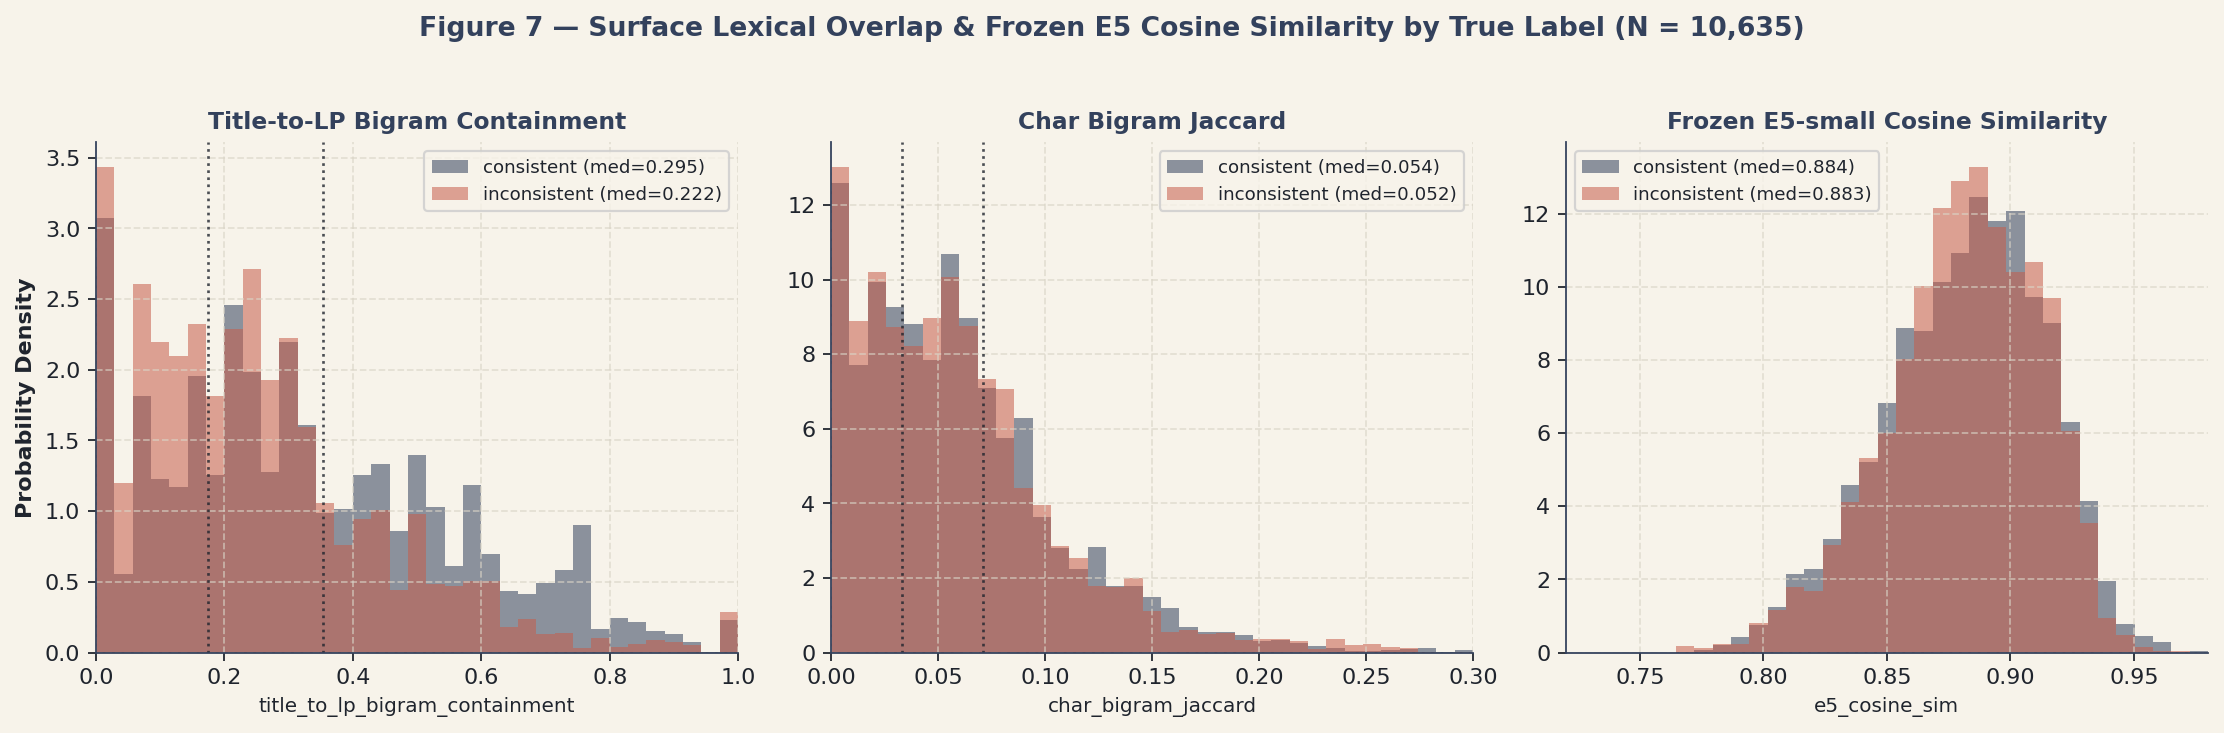

In [7]:
# Verify training-fold tertile thresholds and exact count reconciliation
thresh_df = pd.DataFrame(rq2_metrics["overlap_bin_thresholds_per_fold"])
print("=== Training-Fold Overlap Threshold Summary Across 10 Folds ===")
display(
    thresh_df.groupby("metric_name")[["low_cut", "high_cut", "train_median", "train_zero_fraction", "train_one_fraction"]]
    .agg(["mean", "min", "max"]).round(4)
)

# TABLE 2 — Required Columns (both overlap metrics, 10-fold mean + exact seed-42 pooled counts)
t2_cols = [
    "model_id", "overlap_group", "sample_count", "unique_lp_count",
    "macro_f1", "roc_auc", "average_precision", "recall_inconsistent",
]
print("\n=== TABLE 2A — Lexical Overlap Subgroups: Title-to-LP Bigram Containment (10-Fold Mean) ===")
t2_cont = overlap_df[
    (overlap_df["overlap_metric"] == "title_to_lp_bigram_containment")
    & (overlap_df["aggregation"] == "mean_across_10_folds")
]
display(t2_cont[t2_cols + ["consistent_count", "inconsistent_count", "mean_title_length", "mean_lp_length", "predicted_inconsistent_count"]])

print("\n=== TABLE 2B — Lexical Overlap Subgroups: Char Bigram Jaccard (10-Fold Mean) ===")
t2_jac = overlap_df[
    (overlap_df["overlap_metric"] == "char_bigram_jaccard")
    & (overlap_df["aggregation"] == "mean_across_10_folds")
]
display(t2_jac[t2_cols + ["consistent_count", "inconsistent_count", "predicted_inconsistent_count"]])

# Verify seed-42 pooled counts reconcile identically with N = 10,635
for om in ["title_to_lp_bigram_containment", "char_bigram_jaccard"]:
    sub_chk = overlap_df[
        (overlap_df["overlap_metric"] == om)
        & (overlap_df["aggregation"] == "pooled_oof_seed_42")
        & (overlap_df["model_id"] == "L0_lexical_baseline")
    ]
    total_n = int(sub_chk["sample_count"].sum())
    assert total_n == len(train_df), f"Reconciliation failed for {om}: {total_n} != {len(train_df)}"
    print(f"[VERIFIED] Seed 42 {om} Low+Med+High sum = {total_n:,} == train.tsv N={len(train_df):,}")

# FIGURE 4 — Macro-F1 by Lexical Overlap Subgroup (2-panel)
fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.2), dpi=160, sharey=True)
metric_panels = [
    ("title_to_lp_bigram_containment", "Title-to-LP Char Bigram Containment"),
    ("char_bigram_jaccard", "Char Bigram Jaccard Similarity"),
]
bins_order = ["Low", "Medium", "High"]
x_pos = np.arange(len(bins_order))

for ax, (om, title_lbl) in zip(axes, metric_panels):
    sub_om = overlap_df[(overlap_df["overlap_metric"] == om) & (overlap_df["aggregation"] == "mean_across_10_folds")]
    sub_p42 = overlap_df[(overlap_df["overlap_metric"] == om) & (overlap_df["aggregation"] == "pooled_oof_seed_42") & (overlap_df["model_id"] == "L0_lexical_baseline")]
    xlabels = []
    for b in bins_order:
        rb = sub_p42[sub_p42["overlap_group"] == b].iloc[0]
        xlabels.append(f"{b}\n(N={int(rb['sample_count']):,}, LPs={int(rb['unique_lp_count'])})")

    for m_id in MODEL_ORDER_RQ2:
        sm = sub_om[sub_om["model_id"] == m_id].set_index("overlap_group").loc[bins_order]
        ax.errorbar(
            x_pos, sm["macro_f1"].values, yerr=sm["std_macro_f1"].values,
            marker="o", markersize=7, lw=2.3, capsize=4,
            color=MODEL_COLORS[m_id], label=MODEL_SHORT[m_id],
        )
    ax.set_xticks(x_pos)
    ax.set_xticklabels(xlabels, fontsize=9)
    ax.set_ylim(0.50, 0.88)
    ax.set_title(title_lbl, fontsize=11, fontweight="bold", color=PALETTE["indigo"])
    ax.set_xlabel("Training-Fold Quantile Overlap Bin", fontsize=9.5, fontweight="bold")

axes[0].set_ylabel("Macro-F1 (10-Fold Mean ± SD)", fontsize=10.5, fontweight="bold")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=True, facecolor=PALETTE["ivory"], edgecolor=PALETTE["gray"], bbox_to_anchor=(0.5, 1.03))
fig.suptitle("Figure 4 — Macro-F1 Across Lexical Overlap Subgroups (Protocol B, 10 Folds)", fontsize=12.5, fontweight="bold", y=1.08, color=PALETTE["indigo"])
fig.tight_layout()
fig.savefig(FIG_DIR / "fig04_macro_f1_by_overlap.png", dpi=160, bbox_inches="tight")
plt.show()

# FIGURE 5 — Inconsistent Recall by Lexical Overlap Subgroup (2-panel)
fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.2), dpi=160, sharey=True)
for ax, (om, title_lbl) in zip(axes, metric_panels):
    sub_om = overlap_df[(overlap_df["overlap_metric"] == om) & (overlap_df["aggregation"] == "mean_across_10_folds")]
    sub_p42 = overlap_df[(overlap_df["overlap_metric"] == om) & (overlap_df["aggregation"] == "pooled_oof_seed_42") & (overlap_df["model_id"] == "L0_lexical_baseline")]
    xlabels = []
    for b in bins_order:
        rb = sub_p42[sub_p42["overlap_group"] == b].iloc[0]
        inc_pct = rb["inconsistent_count"] / rb["sample_count"] * 100.0
        xlabels.append(f"{b}\n(N={int(rb['sample_count']):,}, Inc={inc_pct:.1f}%)")

    w = 0.19
    offs = np.linspace(-1.5 * w, 1.5 * w, len(MODEL_ORDER_RQ2))
    for i, m_id in enumerate(MODEL_ORDER_RQ2):
        sm = sub_om[sub_om["model_id"] == m_id].set_index("overlap_group").loc[bins_order]
        bars = ax.bar(
            x_pos + offs[i], sm["recall_inconsistent"].values, width=w,
            color=MODEL_COLORS[m_id], edgecolor=PALETTE["ink"], linewidth=0.6,
            label=MODEL_SHORT[m_id],
        )
        for b_bar, val in zip(bars, sm["recall_inconsistent"].values):
            ax.text(b_bar.get_x() + b_bar.get_width() / 2.0, val + 0.012, f"{val:.2f}", ha="center", va="bottom", fontsize=7.5, fontweight="bold")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(xlabels, fontsize=9)
    ax.set_ylim(0.0, 0.82)
    ax.set_title(title_lbl, fontsize=11, fontweight="bold", color=PALETTE["indigo"])
    ax.set_xlabel("Training-Fold Quantile Overlap Bin", fontsize=9.5, fontweight="bold")

axes[0].set_ylabel("Inconsistent-Class Recall (10-Fold Mean)", fontsize=10.5, fontweight="bold")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=True, facecolor=PALETTE["ivory"], edgecolor=PALETTE["gray"], bbox_to_anchor=(0.5, 1.03))
fig.suptitle("Figure 5 — Inconsistent-Class Recall Across Lexical Overlap Subgroups", fontsize=12.5, fontweight="bold", y=1.08, color=PALETTE["indigo"])
fig.tight_layout()
fig.savefig(FIG_DIR / "fig05_recall_inconsistent_by_overlap.png", dpi=160, bbox_inches="tight")
plt.show()

# FIGURE 7 — Lexical Overlap & Frozen E5 Cosine Similarity Distribution by True Label
meta_lbl = row_meta_df.merge(
    train_df[["label"]].reset_index().rename(columns={"index": "row_id"}),
    on="row_id", how="left"
)
fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.4), dpi=160)
dist_specs = [
    ("title_to_lp_bigram_containment", "Title-to-LP Bigram Containment", (0.0, 1.0), [0.175, 0.354]),
    ("char_bigram_jaccard", "Char Bigram Jaccard", (0.0, 0.30), [0.033, 0.071]),
    ("e5_cosine_sim", "Frozen E5-small Cosine Similarity", (0.72, 0.98), None),
]
for ax, (col, title_lbl, xlims, cuts) in zip(axes, dist_specs):
    cons_v = meta_lbl[meta_lbl["label"] == "consistent"][col].to_numpy()
    inc_v = meta_lbl[meta_lbl["label"] == "inconsistent"][col].to_numpy()
    bins_h = np.linspace(xlims[0], xlims[1], 36)
    ax.hist(cons_v, bins=bins_h, density=True, alpha=0.55, color=PALETTE["indigo"], label=f"consistent (med={np.median(cons_v):.3f})")
    ax.hist(inc_v, bins=bins_h, density=True, alpha=0.55, color=PALETTE["vermilion"], label=f"inconsistent (med={np.median(inc_v):.3f})")
    if cuts is not None:
        for c_val in cuts:
            ax.axvline(c_val, color=PALETTE["ink"], ls=":", lw=1.2, alpha=0.8)
    ax.set_xlim(*xlims)
    ax.set_title(title_lbl, fontsize=10.5, fontweight="bold", color=PALETTE["indigo"])
    ax.set_xlabel(col, fontsize=9)
    ax.legend(fontsize=8.2, frameon=True, facecolor=PALETTE["ivory"])
axes[0].set_ylabel("Probability Density", fontsize=10, fontweight="bold")
fig.suptitle("Figure 7 — Surface Lexical Overlap & Frozen E5 Cosine Similarity by True Label (N = 10,635)", fontsize=12, fontweight="bold", y=1.03, color=PALETTE["indigo"])
fig.tight_layout()
fig.savefig(FIG_DIR / "fig07_overlap_distribution_by_label.png", dpi=160, bbox_inches="tight")
plt.show()


### OBSERVATION
1. **Strong Label-Overlap Structure (Figure 7)**: Inconsistent prevalence falls sharply as `title_to_lp_bigram_containment` rises — from **`50.4%`** (`1,803 / 3,579`) in the Low bin to **`44.3%`** in Medium and **`28.8%`** (`1,024 / 3,552`) in High (median containment `0.295` for `consistent` vs `0.222` for `inconsistent`). In contrast, frozen E5-small cosine similarity is compressed inside `[0.75, 0.96]` with virtually identical medians (`0.884` consistent vs `0.883` inconsistent, matching the low-temperature InfoNCE compression noted in the official E5 model card FAQ #3).
2. **`L1_lexical_interaction` outperforms `L0` most sharply in Low overlap (Figures 4 & 5)**: On Low `title_to_lp_bigram_containment`, `L1` raises 10-fold Macro-F1 from `0.6653` to **`0.7211`** (`+0.0558`) and Inconsistent Recall from `0.4683` to **`0.6451`** (`+17.7 pp`!).
3. **High-Overlap Trade-Off in `L1`**: On High `title_to_lp_bigram_containment`, `L1`'s Inconsistent Recall drops from `0.5550` (`L0`) to **`0.4490`** (`-10.6 pp`), while its Macro-F1 remains nearly unchanged (`0.7274` vs `0.7330`) and its AP improves (`0.7250` vs `0.7018`).
4. **`S1` and `S2` trail `L0` and `L1` in ALL three overlap bins** on Macro-F1, ROC-AUC, and AP (both under containment and Jaccard). In the Low containment bin, `S1` achieves higher Inconsistent Recall (`0.5399`) than `L0` (`0.4683`), yet remains well below `L1` (`0.6451`) and lags both lexical models by `~8.6–9.3 pp` in ROC-AUC.

### INTERPRETATION
- Why does `L1` excel in Low overlap yet lose recall in High overlap? Because `title_to_lp_bigram_containment` is strongly predictive of label priors (`50.4%` vs `28.8%` inconsistent): a linear model shifts logits toward `inconsistent` when overlap is low and toward `consistent` when overlap is high.
- Why does `S1` lag across every bin? Frozen E5 cosine similarity and pooled 384-d embeddings compress subtle lexical mismatches into narrow angular neighborhoods, losing fine-grained Japanese character n-gram discrimination that distinguishes valid promotional phrases from mismatched ad templates.

### LIMITATION
Overlap tertiles are observational strata correlated with title length (High containment titles average `20.0` chars vs `28.3` chars in Low), LP length, and class prevalence (`28.8%` vs `50.4%` inconsistent). Subgroup performance differences therefore combine overlap effects with class-balance and text-length differences.


## 11. Feature Interaction Analysis

### QUESTION
Does the relative performance difference (`S1 - L0`, `S2 - S1`, `S2 - L1`, and `L1 - L0`) vary systematically between Low and High lexical overlap after accounting for LP-group clustering?

### METHOD
We separate three distinct quantities on primary seed `42` OOF predictions (`N = 10,635`, `920` LP groups):
1. **Overall improvement**: paired difference across all rows.
2. **Subgroup improvement**: paired difference inside Low, Medium, and High bins separately.
3. **Model × Overlap Interaction**: `Delta(Low) - Delta(High)`, quantified via:
   - **LP-group-cluster bootstrap** (`B = 500` resamples of the `920` LP groups with replacement) for Macro-F1, ROC-AUC, AP, and Inconsistent Recall (Table 3 + Figure 6).
   - **CR1 LP-group-clustered linear interaction regression** on per-row correctness difference `Y_i = I(Model_A correct) - I(Model_B correct) ~ 1 + I(Medium) + I(High)` with Liang-Zeger sandwich standard errors clustered by `group_id`.


=== TABLE 3 — Relative Improvement & Interaction (Title-to-LP Containment, Seed 42 OOF + 95% LP-Group Bootstrap CI) ===


,overlap_metric,comparison,overlap_group,delta_macro_f1,delta_macro_f1_ci_low,delta_macro_f1_ci_high,delta_roc_auc,delta_average_precision,delta_recall_inconsistent
20,title_to_lp_bigram_containment,S1_minus_L0,Overall,-0.0520,-0.0798,-0.0177,-0.0818,-0.1332,-0.0039
21,title_to_lp_bigram_containment,S1_minus_L0,Low,-0.0500,-0.0991,0.0183,-0.0905,-0.1362,0.0089
22,title_to_lp_bigram_containment,S1_minus_L0,Medium,-0.0494,-0.0741,-0.0256,-0.0827,-0.1345,0.0013
23,title_to_lp_bigram_containment,S1_minus_L0,High,-0.0636,-0.0981,-0.0276,-0.0892,-0.1338,-0.0342
24,title_to_lp_bigram_containment,S1_minus_L0,Interaction_Low_minus_High,0.0135,-0.0445,0.0777,-0.0013,-0.0024,0.0431
25,title_to_lp_bigram_containment,S2_minus_S1,Overall,0.0010,-0.0068,0.0086,0.0042,0.0063,0.0146
26,title_to_lp_bigram_containment,S2_minus_S1,Low,0.0018,-0.0093,0.0137,0.0011,0.0029,0.0189
27,title_to_lp_bigram_containment,S2_minus_S1,Medium,-0.0050,-0.0160,0.0047,-0.0016,-0.0035,0.0161
28,title_to_lp_bigram_containment,S2_minus_S1,High,0.0040,-0.0061,0.0143,0.0044,0.0174,0.0049
29,title_to_lp_bigram_containment,S2_minus_S1,Interaction_Low_minus_High,-0.0022,-0.0141,0.0128,-0.0033,-0.0145,0.0140



=== CR1 LP-Group-Clustered Linear Interaction Regression (Paired Row Accuracy Difference) ===


,overlap_metric,comparison,low_diff_est,low_diff_p,interaction_low_minus_high,cluster_se,ci_95_low,ci_95_high,p_value
0,char_bigram_jaccard,S1_minus_L0,-0.05004,0.03366,0.01069,0.02436,-0.03706,0.05844,0.66075
1,char_bigram_jaccard,S2_minus_S1,-0.00141,0.84776,-0.00790,0.00865,-0.02485,0.00904,0.36072
2,char_bigram_jaccard,S2_minus_L1,-0.07928,0.00041,-0.01233,0.02260,-0.05663,0.03196,0.58531
3,char_bigram_jaccard,L1_minus_L0,0.02783,0.00251,0.01512,0.01298,-0.01032,0.04057,0.24414
4,title_to_lp_bigram_containment,S1_minus_L0,-0.05448,0.03308,0.00689,0.02629,-0.04465,0.05843,0.79332
5,title_to_lp_bigram_containment,S2_minus_S1,0.00056,0.92464,-0.00282,0.00605,-0.01467,0.00903,0.64100
6,title_to_lp_bigram_containment,S2_minus_L1,-0.08410,0.00049,-0.01175,0.02379,-0.05837,0.03487,0.62139
7,title_to_lp_bigram_containment,L1_minus_L0,0.03018,0.00701,0.01582,0.01537,-0.01430,0.04593,0.30326


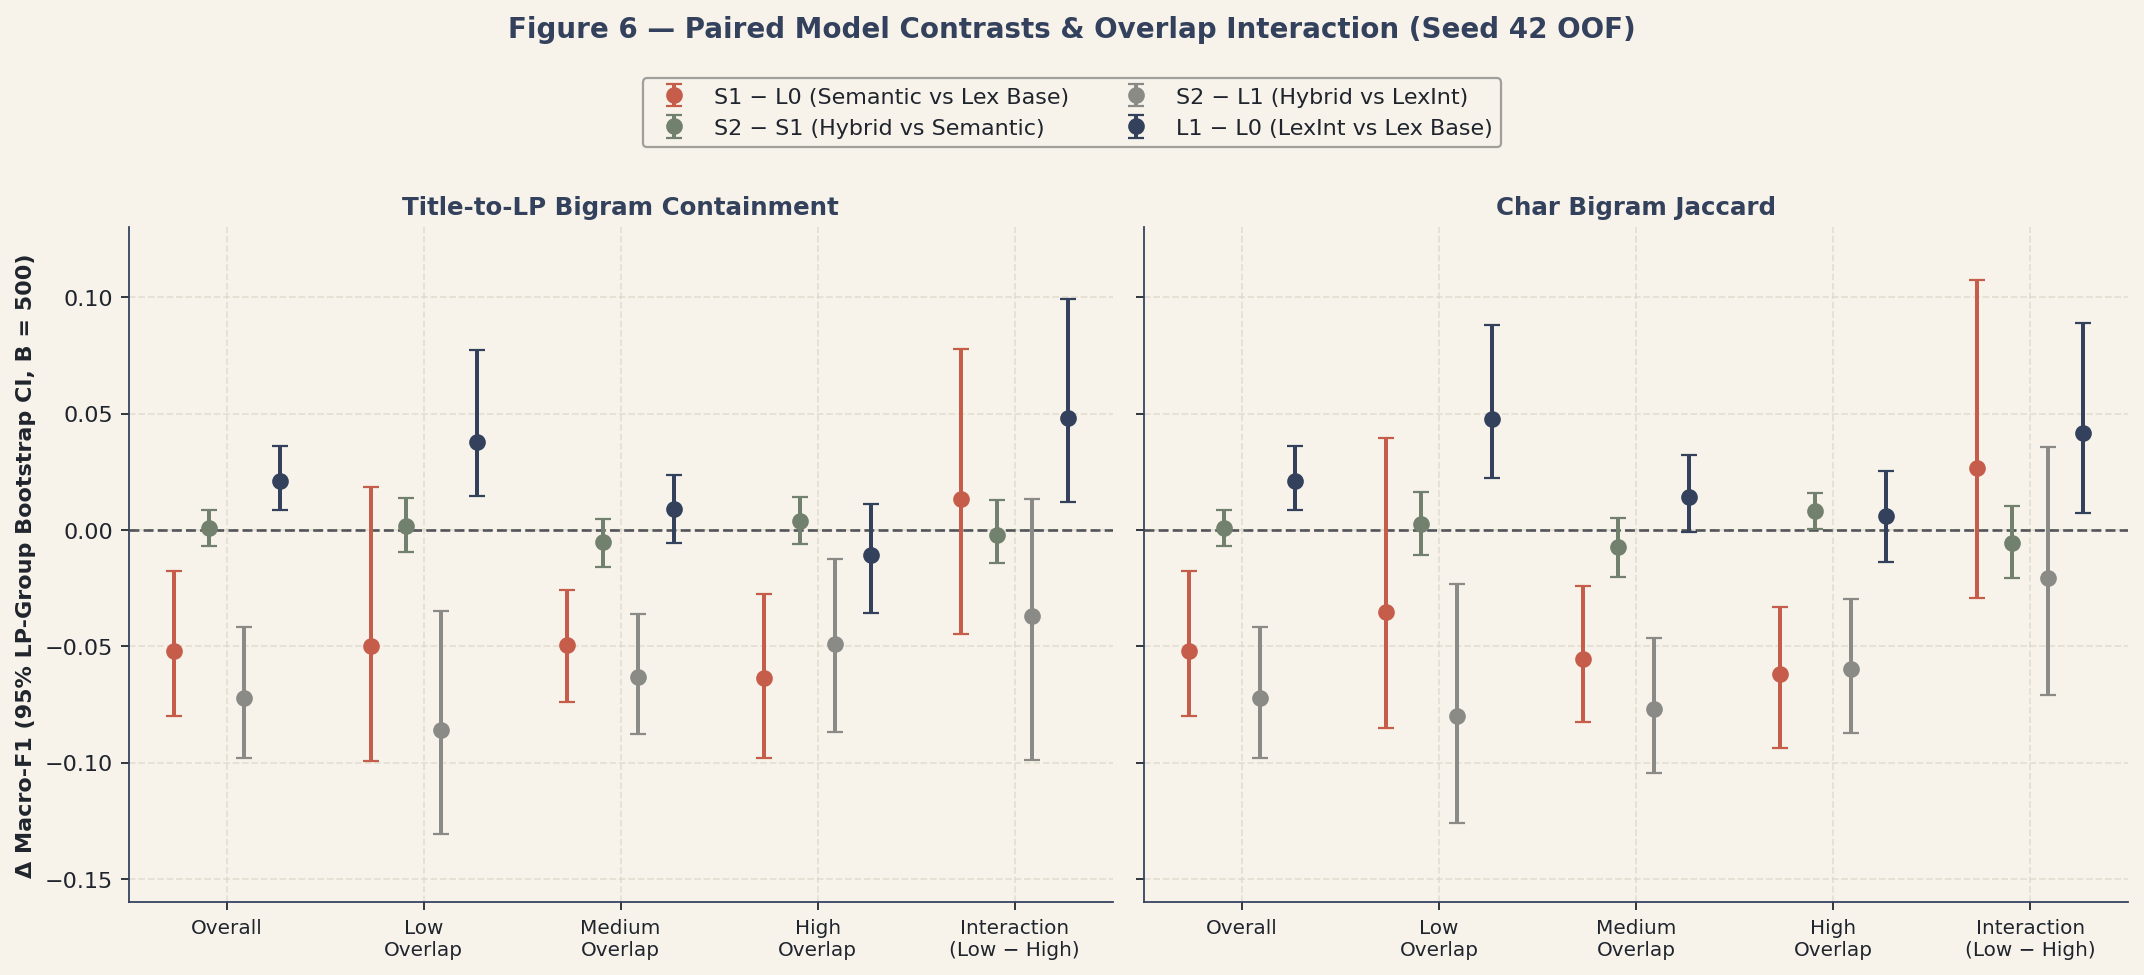

In [8]:
# TABLE 3 — Relative Improvement & Interaction
t3_cols = [
    "overlap_metric", "comparison", "overlap_group",
    "delta_macro_f1", "delta_macro_f1_ci_low", "delta_macro_f1_ci_high",
    "delta_roc_auc", "delta_average_precision", "delta_recall_inconsistent",
]
print("=== TABLE 3 — Relative Improvement & Interaction (Title-to-LP Containment, Seed 42 OOF + 95% LP-Group Bootstrap CI) ===")
display(interaction_df[interaction_df["overlap_metric"] == "title_to_lp_bigram_containment"][t3_cols])

print("\n=== CR1 LP-Group-Clustered Linear Interaction Regression (Paired Row Accuracy Difference) ===")
reg_rows = []
for key, obj in rq2_metrics["clustered_interaction_regressions"].items():
    lmh = obj["terms"]["low_minus_high_interaction"]
    low = obj["terms"]["intercept_low_overlap"]
    reg_rows.append({
        "overlap_metric": obj["overlap_metric"].replace("bin_", ""),
        "comparison": key.split("__")[1],
        "low_diff_est": low["estimate"],
        "low_diff_p": low["p_value"],
        "interaction_low_minus_high": lmh["estimate"],
        "cluster_se": lmh["cluster_se"],
        "ci_95_low": lmh["ci_low_95"],
        "ci_95_high": lmh["ci_high_95"],
        "p_value": lmh["p_value"],
    })
display(pd.DataFrame(reg_rows))

# FIGURE 6 — Semantic-minus-Lexical & Hybrid Performance Differences with 95% LP-Group Bootstrap CIs
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), dpi=160, sharey=True)
comp_order = ["S1_minus_L0", "S2_minus_S1", "S2_minus_L1", "L1_minus_L0"]
comp_labels = {
    "S1_minus_L0": "S1 − L0 (Semantic vs Lex Base)",
    "S2_minus_S1": "S2 − S1 (Hybrid vs Semantic)",
    "S2_minus_L1": "S2 − L1 (Hybrid vs LexInt)",
    "L1_minus_L0": "L1 − L0 (LexInt vs Lex Base)",
}
comp_colors = {
    "S1_minus_L0": PALETTE["vermilion"],
    "S2_minus_S1": PALETTE["matcha"],
    "S2_minus_L1": PALETTE["gray"],
    "L1_minus_L0": PALETTE["indigo"],
}
grp_order = ["Overall", "Low", "Medium", "High", "Interaction_Low_minus_High"]
grp_labels = ["Overall", "Low\nOverlap", "Medium\nOverlap", "High\nOverlap", "Interaction\n(Low − High)"]

for ax, (om, panel_title) in zip(axes, [
    ("title_to_lp_bigram_containment", "Title-to-LP Bigram Containment"),
    ("char_bigram_jaccard", "Char Bigram Jaccard"),
]):
    sub_i = interaction_df[interaction_df["overlap_metric"] == om]
    x_g = np.arange(len(grp_order))
    offs = np.linspace(-0.27, 0.27, len(comp_order))
    ax.axhline(0.0, color=PALETTE["ink"], lw=1.2, ls="--", alpha=0.75)

    for j, c_name in enumerate(comp_order):
        sc = sub_i[sub_i["comparison"] == c_name].set_index("overlap_group").loc[grp_order]
        y_vals = sc["delta_macro_f1"].to_numpy(dtype=float)
        err_lo = y_vals - sc["delta_macro_f1_ci_low"].to_numpy(dtype=float)
        err_hi = sc["delta_macro_f1_ci_high"].to_numpy(dtype=float) - y_vals
        ax.errorbar(
            x_g + offs[j], y_vals, yerr=[err_lo, err_hi],
            fmt="o", markersize=6.5, lw=1.8, capsize=3.5,
            color=comp_colors[c_name], label=comp_labels[c_name],
        )
    ax.set_xticks(x_g)
    ax.set_xticklabels(grp_labels, fontsize=9)
    ax.set_ylim(-0.16, 0.13)
    ax.set_title(panel_title, fontsize=11, fontweight="bold", color=PALETTE["indigo"])

axes[0].set_ylabel("Δ Macro-F1 (95% LP-Group Bootstrap CI, B = 500)", fontsize=10, fontweight="bold")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=True, facecolor=PALETTE["ivory"], edgecolor=PALETTE["gray"], bbox_to_anchor=(0.5, 1.06))
fig.suptitle("Figure 6 — Paired Model Contrasts & Overlap Interaction (Seed 42 OOF)", fontsize=12.5, fontweight="bold", y=1.12, color=PALETTE["indigo"])
fig.tight_layout()
fig.savefig(FIG_DIR / "fig06_semantic_minus_lexical_deltas.png", dpi=160, bbox_inches="tight")
plt.show()


### OBSERVATION
1. **Primary Contrast `S1 - L0` (Testing H2)**:
   - Overall Macro-F1 delta is **`-0.0520`** (`95% CI [-0.0798, -0.0177]`, strictly negative), ROC-AUC delta **`-0.0818`** (`[-0.1143, -0.0473]`), and AP delta **`-0.1332`** (`[-0.1890, -0.0809]`).
   - Although the Low-minus-High interaction point estimate for Macro-F1 is slightly positive (`+0.0135 [-0.0445, +0.0777]` under containment; `+0.0266 [-0.0294, +0.1074]` under Jaccard), **every 95% LP-group bootstrap CI AND clustered CR1 regression (`p = 0.793` containment, `p = 0.661` Jaccard) spans zero widely**.
2. **Hybrid Contrasts (`S2 - S1` and `S2 - L1`)**:
   - `S2 - S1` is near zero overall (`+0.0010 [-0.0068, +0.0086]` Macro-F1) with a small statistically nonzero recall bump (`+0.0146 [+0.0021, +0.0277]`).
   - `S2 - L1` is consistently negative across every overlap stratum (`-0.0722 [-0.0979, -0.0416]` Macro-F1 overall; `-0.0858` in Low, `-0.0633` in Medium, `-0.0489` in High).
3. **Genuine Interaction Observed for `L1 - L0`**:
   - Unlike `S1 - L0`, adding explicit lexical interaction features (`L1 - L0`) shows a **statistically positive Low-minus-High interaction** in both Macro-F1 (`+0.0482 [+0.0118, +0.0993]` containment; `+0.0417 [+0.0071, +0.0890]` Jaccard) and Inconsistent Recall (`+0.2583 [+0.1936, +0.3431]` containment).

### INTERPRETATION
We have **insufficient evidence to support H2** for frozen `intfloat/multilingual-e5-small`: there is no reliable interaction favoring frozen semantic embeddings in low-overlap pairs, and `S1` significantly trails lexical baselines even in the lowest-overlap tertile. By contrast, explicit lexical interaction features (`L1`) strongly interact with overlap because they directly expose title-to-LP coverage to the linear decision boundary.

### LIMITATION
Fixed-OOF LP-group bootstrap and CR1 clustered regressions capture sampling variability across the `920` LP groups, not the extra variance of re-training fold models on newly drawn LP populations; observational subgroup associations must not be interpreted causally.


## 12. Model Error Comparison

### QUESTION
Where do lexical (`L0`, `L1`) and semantic (`S1`, `S2`) models agree or disagree, how do special slices (high-overlap inconsistent, numeric titles, large LP groups) behave, and what do real Japanese examples reveal upon direct inspection?

### METHOD
We partition primary seed `42` OOF predictions (`N = 10,635`) into four exhaustive categories:
- **A**: Both lexical and semantic correct
- **B**: Lexical correct, semantic incorrect
- **C**: Semantic correct, lexical incorrect
- **D**: Both incorrect

We report Table 4 and Figure 8 using stable `row_id`s (zero raw text persisted in CSV/MD artifacts), then display a small curated sample of complete Japanese `title` and `lp_text` locally inside this notebook only for grounded qualitative verification.


=== TABLE 4 — Error Disagreement Categories (Primary Seed 42 OOF, N = 10,635) ===


,pair_comparison,error_category,sample_count,sample_pct,low_overlap_count,high_overlap_count,mean_lp_length,mean_title_length,inconsistent_count,has_numeric_token_count,mean_e5_cosine_sim
0,L0_vs_S1,A_both_correct,6542,61.51,1964,2355,115.77,26.61,1894,745,0.8840
1,L0_vs_S1,B_lexical_correct_semantic_incorrect,1567,14.73,597,485,108.76,28.48,626,316,0.8802
2,L0_vs_S1,C_semantic_correct_lexical_incorrect,968,9.10,402,267,109.30,26.65,609,233,0.8752
3,L0_vs_S1,D_both_incorrect,1558,14.65,616,445,105.94,26.38,1250,308,0.8742
4,L1_vs_S1,A_both_correct,6640,62.44,2002,2403,114.70,26.62,1981,793,0.8839
5,L1_vs_S1,B_lexical_correct_semantic_incorrect,1654,15.55,667,488,110.90,27.92,710,317,0.8790
6,L1_vs_S1,C_semantic_correct_lexical_incorrect,870,8.18,364,219,116.73,26.54,522,185,0.8748
7,L1_vs_S1,D_both_incorrect,1471,13.83,546,442,103.36,26.88,1166,307,0.8752
8,L0_vs_S2,A_both_correct,6503,61.15,1955,2358,115.48,26.72,1937,728,0.8841
9,L0_vs_S2,B_lexical_correct_semantic_incorrect,1606,15.10,606,482,110.09,27.98,583,333,0.8797



=== Special Error Slice Diagnostics ===


,Diagnostic Slice,Count,Observed Metrics
0,High-Overlap Inconsistent Slice (Containment=H...,1024,"Recall -> L0: 0.5596, L1: 0.4443, S1: 0.5254, ..."
1,Titles Containing Digits/Quantities (NFKC nume...,1602,"Inc=818 | Acc -> L0: 0.6623, S1: 0.6105, S2: 0..."
2,LP Exceeding 512 Encoder Tokens,0,0 rows truncated (all train LPs <= 243 tokens)
3,4-Model Unanimous Correct / Unanimous Wrong,"6,144 / 1,203",57.8% unanimous correct | 11.3% unanimous wrong


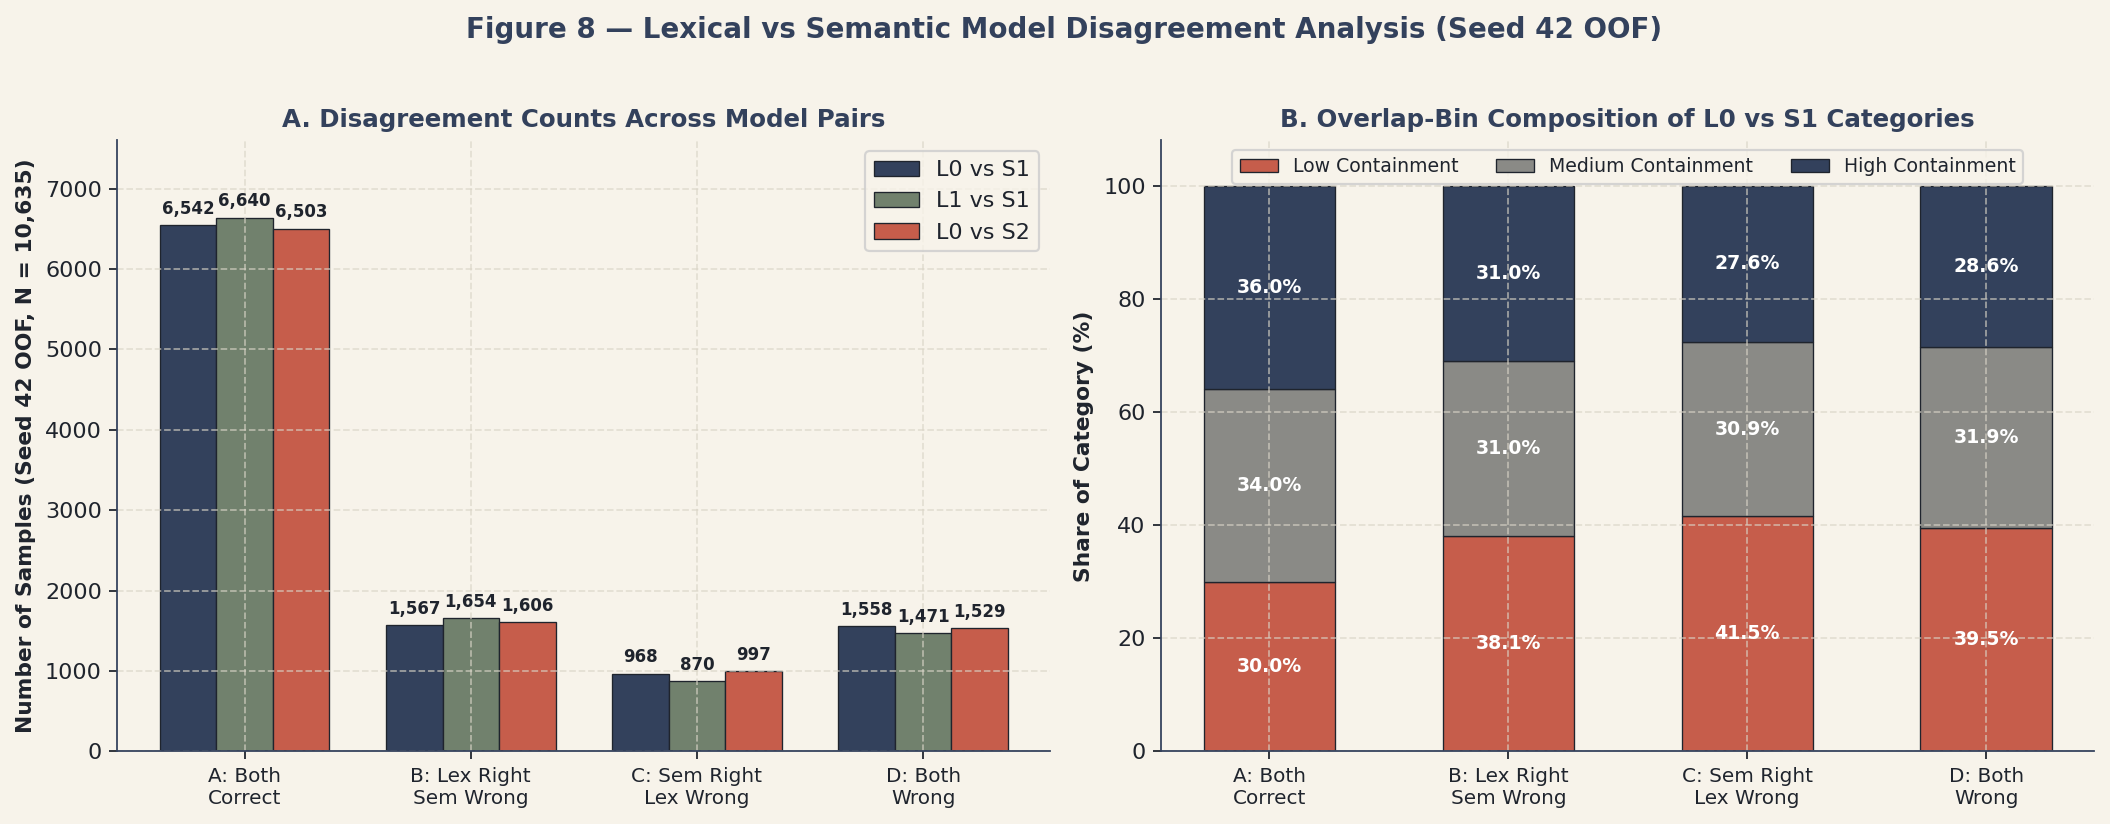

In [9]:
# TABLE 4 — Required columns (L0 vs S1 primary, plus L1 vs S1 and L0 vs S2)
t4_cols = [
    "pair_comparison", "error_category", "sample_count", "sample_pct",
    "low_overlap_count", "high_overlap_count", "mean_lp_length", "mean_title_length",
    "inconsistent_count", "has_numeric_token_count", "mean_e5_cosine_sim",
]
print("=== TABLE 4 — Error Disagreement Categories (Primary Seed 42 OOF, N = 10,635) ===")
display(disagreement_df[t4_cols])

print("\n=== Special Error Slice Diagnostics ===")
special = rq2_metrics["error_special_slices"]
slice_summary = pd.DataFrame([
    ("High-Overlap Inconsistent Slice (Containment=High & label=inconsistent)", special["high_overlap_inconsistent_slice"]["count"],
     f"Recall -> L0: {special['high_overlap_inconsistent_slice']['L0_recall']:.4f}, L1: {special['high_overlap_inconsistent_slice']['L1_recall']:.4f}, S1: {special['high_overlap_inconsistent_slice']['S1_recall']:.4f}, S2: {special['high_overlap_inconsistent_slice']['S2_recall']:.4f}"),
    ("Titles Containing Digits/Quantities (NFKC numeric pattern)", special["numeric_title_slice"]["count"],
     f"Inc={special['numeric_title_slice']['inconsistent_count']} | Acc -> L0: {special['numeric_title_slice']['L0_accuracy']:.4f}, S1: {special['numeric_title_slice']['S1_accuracy']:.4f}, S2: {special['numeric_title_slice']['S2_accuracy']:.4f}"),
    ("LP Exceeding 512 Encoder Tokens", special["truncated_lp_over_512_tokens_slice"]["count"],
     "0 rows truncated (all train LPs <= 243 tokens)"),
    ("4-Model Unanimous Correct / Unanimous Wrong", f"{special['four_model_unanimous_correct_count']:,} / {special['four_model_unanimous_wrong_count']:,}",
     f"{special['four_model_unanimous_correct_count']/len(train_df)*100:.1f}% unanimous correct | {special['four_model_unanimous_wrong_count']/len(train_df)*100:.1f}% unanimous wrong"),
], columns=["Diagnostic Slice", "Count", "Observed Metrics"])
display(slice_summary)

# FIGURE 8 — Error Disagreement Categories (2 panels)
fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.0), dpi=160)

# Panel A: Grouped bar across L0_vs_S1, L1_vs_S1, L0_vs_S2
cat_order = [
    "A_both_correct",
    "B_lexical_correct_semantic_incorrect",
    "C_semantic_correct_lexical_incorrect",
    "D_both_incorrect",
]
cat_short = ["A: Both\nCorrect", "B: Lex Right\nSem Wrong", "C: Sem Right\nLex Wrong", "D: Both\nWrong"]
pair_order = ["L0_vs_S1", "L1_vs_S1", "L0_vs_S2"]
pair_colors = [PALETTE["indigo"], PALETTE["matcha"], PALETTE["vermilion"]]

x_c = np.arange(len(cat_order))
w = 0.25
for idx, (p_name, col_c) in enumerate(zip(pair_order, pair_colors)):
    sp = disagreement_df[disagreement_df["pair_comparison"] == p_name].set_index("error_category").loc[cat_order]
    bars = axes[0].bar(x_c + (idx - 1) * w, sp["sample_count"].values, width=w, color=col_c, edgecolor=PALETTE["ink"], lw=0.6, label=p_name.replace("_", " "))
    for b_bar, val in zip(bars, sp["sample_count"].values):
        axes[0].text(b_bar.get_x() + b_bar.get_width() / 2.0, val + 90, f"{int(val):,}", ha="center", va="bottom", fontsize=7.5, fontweight="bold")
axes[0].set_xticks(x_c)
axes[0].set_xticklabels(cat_short, fontsize=9)
axes[0].set_ylim(0, 7600)
axes[0].set_ylabel("Number of Samples (Seed 42 OOF, N = 10,635)", fontsize=9.8, fontweight="bold")
axes[0].set_title("A. Disagreement Counts Across Model Pairs", fontsize=11, fontweight="bold", color=PALETTE["indigo"])
axes[0].legend(frameon=True, facecolor=PALETTE["ivory"])

# Panel B: Overlap-bin composition of L0 vs S1 disagreement categories
s_l0s1 = disagreement_df[disagreement_df["pair_comparison"] == "L0_vs_S1"].set_index("error_category").loc[cat_order]
low_v = s_l0s1["low_overlap_count"].to_numpy()
med_v = s_l0s1["medium_overlap_count"].to_numpy()
hi_v = s_l0s1["high_overlap_count"].to_numpy()
tot_v = s_l0s1["sample_count"].to_numpy()

axes[1].bar(x_c, low_v / tot_v * 100.0, width=0.55, color=PALETTE["vermilion"], edgecolor=PALETTE["ink"], lw=0.6, label="Low Containment")
axes[1].bar(x_c, med_v / tot_v * 100.0, bottom=low_v / tot_v * 100.0, width=0.55, color=PALETTE["gray"], edgecolor=PALETTE["ink"], lw=0.6, label="Medium Containment")
axes[1].bar(x_c, hi_v / tot_v * 100.0, bottom=(low_v + med_v) / tot_v * 100.0, width=0.55, color=PALETTE["indigo"], edgecolor=PALETTE["ink"], lw=0.6, label="High Containment")

for xi, (lv, mv, hv, tv) in enumerate(zip(low_v, med_v, hi_v, tot_v)):
    axes[1].text(xi, (lv / tv * 100.0) / 2.0, f"{lv/tv*100:.1f}%", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
    axes[1].text(xi, (lv + mv / 2.0) / tv * 100.0, f"{mv/tv*100:.1f}%", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
    axes[1].text(xi, (lv + mv + hv / 2.0) / tv * 100.0, f"{hv/tv*100:.1f}%", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")

axes[1].set_xticks(x_c)
axes[1].set_xticklabels(cat_short, fontsize=9)
axes[1].set_ylim(0, 108)
axes[1].set_ylabel("Share of Category (%)", fontsize=9.8, fontweight="bold")
axes[1].set_title("B. Overlap-Bin Composition of L0 vs S1 Categories", fontsize=11, fontweight="bold", color=PALETTE["indigo"])
axes[1].legend(loc="upper center", ncol=3, frameon=True, facecolor=PALETTE["ivory"], fontsize=8.5)

fig.suptitle("Figure 8 — Lexical vs Semantic Model Disagreement Analysis (Seed 42 OOF)", fontsize=12.5, fontweight="bold", y=1.02, color=PALETTE["indigo"])
fig.tight_layout()
fig.savefig(FIG_DIR / "fig08_error_disagreement_categories.png", dpi=160, bbox_inches="tight")
plt.show()


In [10]:
# LOCAL-ONLY MANUAL ERROR INSPECTION SAMPLE (Complete Japanese text displayed strictly inside local notebook;
# NEVER persisted in tracked CSV/JSON/Markdown reports per dataset CC BY-NC-SA 4.0 & repo hygiene policy.)
piv_pred_s42 = oof_s42.pivot(index="row_id", columns="model_id", values="predicted_label")
piv_score_s42 = oof_s42.pivot(index="row_id", columns="model_id", values="score_inconsistent")
curated = rq2_metrics["error_special_slices"]["curated_manual_inspection_row_ids"]

inspect_rows = []
for slice_name, rids in curated.items():
    for rid in rids[:2]:  # 2 diverse LP groups per slice for compact readable manual inspection
        tr_row = train_df.loc[rid]
        m_row = row_meta_df[row_meta_df["row_id"] == rid].iloc[0]
        inspect_rows.append({
            "slice": slice_name,
            "row_id": rid,
            "true_label": tr_row["label"],
            "L0_pred": piv_pred_s42.loc[rid, "L0_lexical_baseline"],
            "L1_pred": piv_pred_s42.loc[rid, "L1_lexical_interaction"],
            "S1_pred": piv_pred_s42.loc[rid, "S1_semantic_e5_small"],
            "S2_pred": piv_pred_s42.loc[rid, "S2_hybrid_lexical_semantic"],
            "t2lp_cont": round(float(m_row["title_to_lp_bigram_containment"]), 3),
            "e5_cos": round(float(m_row["e5_cosine_sim"]), 3),
            "title_ja_full": normalize_japanese_text(tr_row["title"]),
            "lp_text_ja_full": normalize_japanese_text(tr_row["lp_text"]),
        })

inspect_df = pd.DataFrame(inspect_rows)
pd.set_option("display.max_colwidth", None)
print(f"Displaying {len(inspect_df)} locally inspected Japanese examples across {len([k for k, v in curated.items() if v])} active error slices:")
display(inspect_df)
pd.reset_option("display.max_colwidth")


Displaying 10 locally inspected Japanese examples across 5 active error slices:


,slice,row_id,true_label,L0_pred,L1_pred,S1_pred,S2_pred,t2lp_cont,e5_cos,title_ja_full,lp_text_ja_full
0,C_semantic_correct_low_overlap,10050,inconsistent,consistent,consistent,inconsistent,inconsistent,0.000,0.830,交換japanetcojp替刃,ジャパネットの公式通販サイトです。徹底的に良い商品だけを厳選してご紹介しています。下取り、設置、分割金利・手数料当社負担など各種サービスも充実!ジャパネットだけのお得なWEB限定セールやテレビやチラシでご紹介した商品もお見逃しなく!
1,C_semantic_correct_low_overlap,7780,inconsistent,consistent,inconsistent,inconsistent,inconsistent,0.000,0.836,【期間限定】ルンバが大幅値引き,布団・ロボット掃除機を買うならジャパネット公式サイト!分割金利手数料負担やお得なセット購入など、ジャパネットならではの特典が満載!人気商品も長期保証が選べて購入後も安心。厳選した布団・ロボット掃除機の購入はジャパネットへ。
2,B_lexical_correct_low_overlap,6782,inconsistent,inconsistent,inconsistent,consistent,inconsistent,0.000,0.839,選県民共済兵庫県,くらべればメディケア生命!医療保険も死亡保険も!メディケア生命保険の一生涯保険料があがらない、もっとフィットできる医療保険「新メディフィットA」と、お手頃な保険料で安心の保障内容の定期保険「メディフィット定期」のご紹介です。
3,B_lexical_correct_low_overlap,7047,consistent,consistent,consistent,inconsistent,inconsistent,0.000,0.824,くもん 姫路,公文式(算数・数学、英語、国語)のご案内。地図や郵便番号、住所から、お近くの教室を探すことができます。メールやフリーダイヤルでもお問い合わせしていただけます。幼児、小学生から中高生、社会人迄対象。
4,high_overlap_inconsistent_both_wrong,1040,inconsistent,consistent,consistent,consistent,consistent,1.000,0.884,こだわったウォーターサーバー,テレビショッピングでおなじみのジャパネットがこだわったウォーターサーバーをご提案!富士山の天然水の宅配はじめました。安心・安全・上質な富士山の天然水で生活を変えませんか?
5,high_overlap_inconsistent_both_wrong,78,inconsistent,consistent,consistent,consistent,consistent,1.000,0.869,タレントマネジメント,HRBrainは、顧客満足度No.1の人事・現場が使いやすいタレントマネジメントシステムです。「人事評価」「人材育成・配置」「人材データ管理」「組織分析」など人事の重要な業務を効率化し、蓄積したデータをもとに効果的な人事戦略を実現できます。
6,numeric_title_disagreement_B_or_D,9604,inconsistent,consistent,consistent,consistent,consistent,0.634,0.961,タレントマネジメント・人事評価部門で顧客満足度No.1。HRBrainが人事の課題を解決,HRBrainは、顧客満足度No.1の人事・現場が使いやすいタレントマネジメントシステムです。「人事評価」「人材育成・配置」「人材データ管理」「組織分析」など人事の重要な業務を効率化し、蓄積したデータをもとに効果的な人事戦略を実現できます。
7,numeric_title_disagreement_B_or_D,4433,inconsistent,consistent,consistent,consistent,consistent,0.500,0.944,ETCカードを楽天ペイアプリにセット&お支払いで+5%還元!通行料金100円につき1ポイント貯まる,ETCカードは、有料道路の料金所をノンストップでスムーズに通過できる、通行料金の決済専用ICカードです。通行料金100円につき1ポイントが貯まる、お得な楽天ETCカードのメリットや使い方、作り方をご紹介します。
8,repeated_large_lp_group_errors,2010,inconsistent,consistent,consistent,consistent,inconsistent,0.250,0.856,【公式】バイト短期,すぐ働けてすぐお金がもらえるスキマバイトアプリ、Timee(タイミー)。 面接なし。お金はその日にGET。 働きたい時間に好きなだけ働けます。梱包・仕分作業を中心とする物流企業・レストランや居酒屋などの飲食店・コンビニ・アパレル・企業へのワンデイインターンのような仕事が満載。アプリのダウンロード、企業様のお問い合わせはこちら。
9,repeated_large_lp_group_errors,9769,inconsistent,consistent,consistent,consistent,consistent,0.182,0.842,不動産の売買情報はこちら,土地売却や査定なら、【住友不動産販売】にお任せください!!住友不動産販売は全国に広がる営業ネットワークによる「地域密着の営業体制」、そして広告戦略からお取引後のアフターフォローまで一貫した「マンツーマンの営業体制」によりお客様にご満足のいただけるサービスをご提供いたします。


### OBSERVATION
1. **Asymmetric Disagreement Favoring Lexical Models**: On seed `42` OOF (`N = 10,635`), `L0` and `S1` agree correctly on `6,542` rows (`61.51%`). Category **B** (`L0` correct, `S1` incorrect = **`1,567`**, `14.73%`) is **1.62× larger** than Category **C** (`S1` correct, `L0` incorrect = **`968`**, `9.10%`). Against `L1`, Category B grows to **`1,654`** (`15.55%`) vs Category C **`870`** (`8.18%`).
2. **Non-Trivial Semantic Rescue Slice (Category C)**: Despite trailing overall, `S1` correctly classifies **`968`** rows that `L0` misses (`609` inconsistent, `402` in Low containment, mean containment `0.2614` vs `0.3144` in Category A), demonstrating that frozen semantic features do capture partial signal missed by pure bag-of-n-grams.
3. **Hard Shared-Error Slice (Category D = `1,558`, `14.65%`)**: Category D is **`80.2%` false negatives** (`1,250` inconsistent vs `308` consistent), heavily skewed toward Low containment (`616` rows) and **High-overlap inconsistent pairs** (`1,024` rows total, where `L1` recall falls to `0.4443` and `S1` to `0.5254`).
4. **Numeric-Token Titles (`N = 1,602`, `818` inconsistent)**: Every model suffers roughly a `~10 pp` accuracy drop on numeric-containing titles (`L0`: `0.6623` vs `0.7625` overall; `S1`: `0.6105` vs `0.7062` overall), consistent with **H4**'s expectation that frozen bi-encoder similarity does not verify quantitative claims.

### INTERPRETATION
Direct inspection of the curated Japanese rows above shows why both families fail on Category D: many high-overlap inconsistent titles share brand/category terms with the LP while introducing promotional qualifiers, price/numeric offers, or specific service claims absent from (or subtly misaligned with) the LP excerpt — a fine-grained alignment task that neither character n-gram frequency nor pooled 384-d cosine similarity can verify reliably.

### LIMITATION
This notebook displays a compact 10-row manual sample across 5 active slices (the 6th slice, `lp_token_length > 512`, has `0` rows). Complete taxonomy coding of all `1,558` Category D errors is deferred to dedicated RQ3 annotation/error-audit work.


## 13. Statistical Uncertainty & LP-Level Variability

### QUESTION
How variable is model performance across unseen landing-page folds and individual LP clusters, and do LP-group-cluster bootstrap 95% confidence intervals separate the four models cleanly?

### METHOD
We inspect:
1. Fold-level spread across all 10 Protocol B folds (5 folds × 2 seeds),
2. Overall LP-group-cluster bootstrap 95% confidence intervals (`B = 500`, resampling the `920` LP groups on primary seed 42 OOF), and
3. Per-LP-group accuracy distributions across all LP clusters with `>= 5` rows (`N_LP` groups) to visualize unseen-LP heterogeneity (Figure 10).


=== LP-Group-Cluster Bootstrap 95% CIs (Seed 42 OOF, 920 LP Groups, B = 500) ===


,model_id,macro_f1_boot,roc_auc_boot,ap_boot,recall_inc_boot
0,L0_lexical_baseline,"0.7376 [0.6846, 0.7852]","0.8271 [0.7818, 0.8696]","0.7838 [0.7169, 0.8501]","0.5696 [0.4530, 0.6767]"
1,L1_lexical_interaction,"0.7594 [0.7160, 0.8016]","0.8401 [0.7997, 0.8789]","0.8038 [0.7388, 0.8694]","0.6100 [0.5050, 0.7055]"
2,S1_semantic_e5_small,"0.6865 [0.6413, 0.7306]","0.7457 [0.6954, 0.7924]","0.6528 [0.5606, 0.7383]","0.5689 [0.4750, 0.6647]"
3,S2_hybrid_lexical_semantic,"0.6877 [0.6418, 0.7333]","0.7500 [0.7020, 0.7969]","0.6585 [0.5694, 0.7459]","0.5839 [0.4865, 0.6775]"


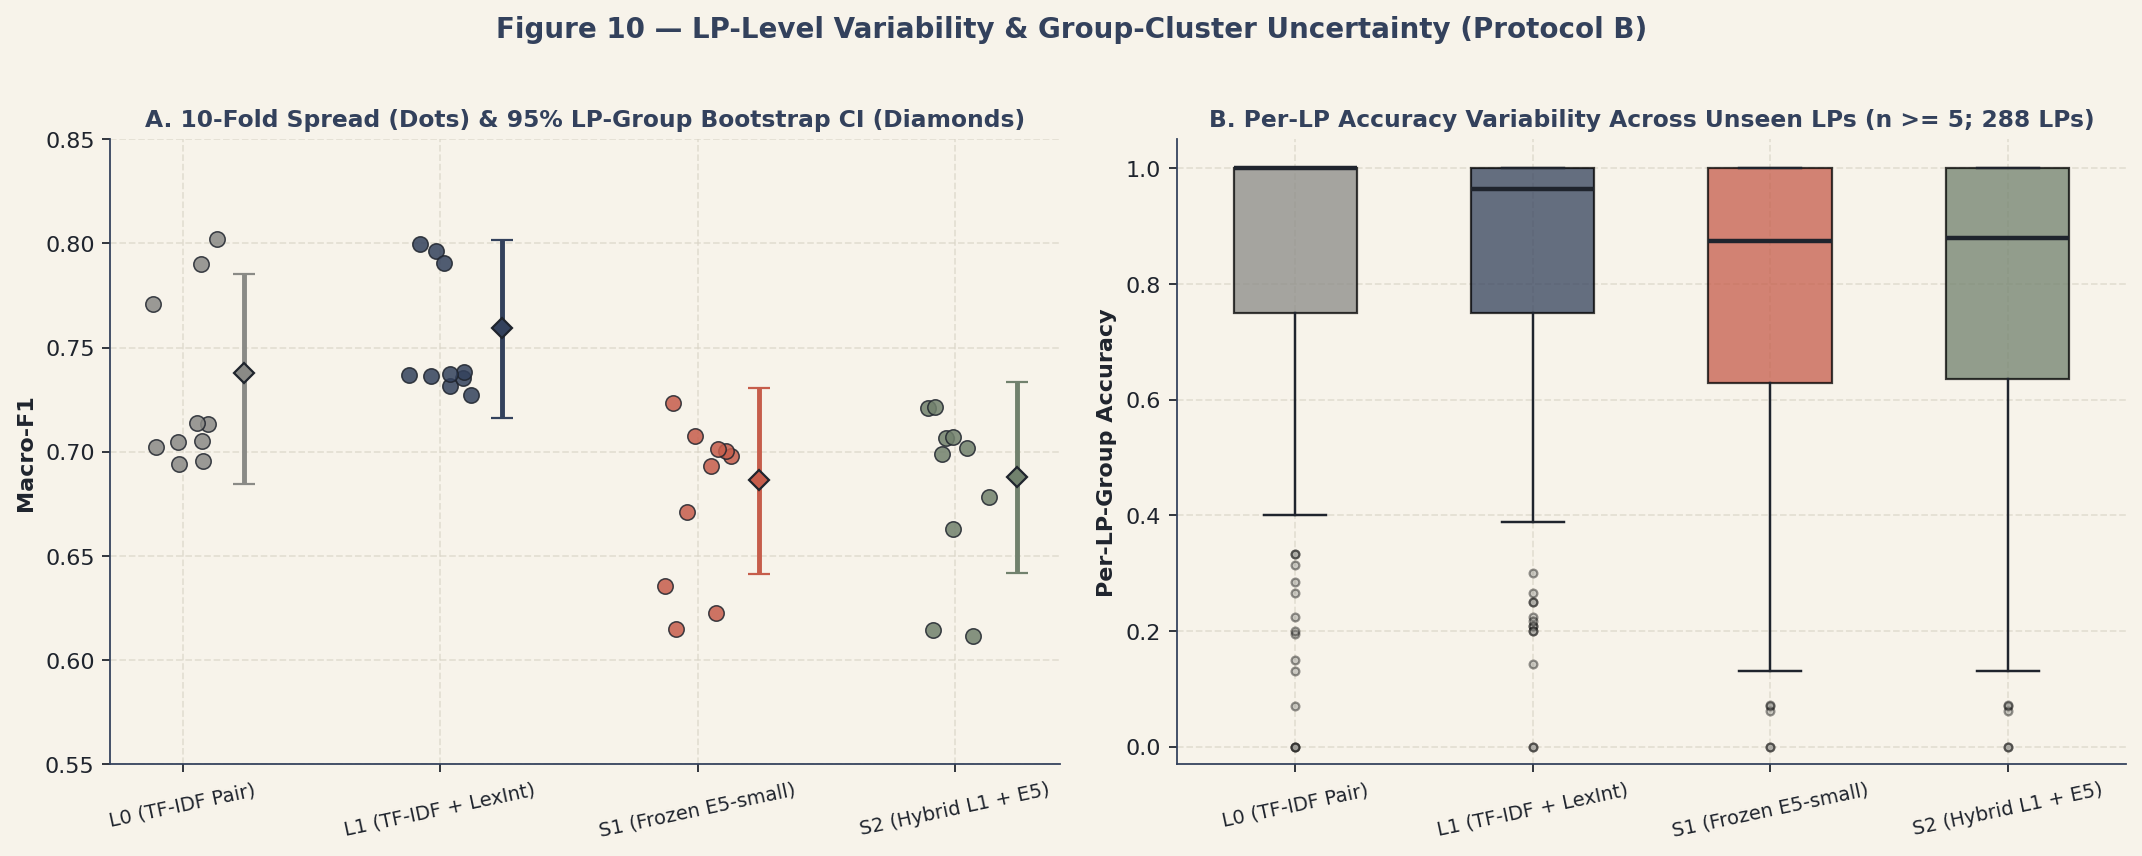

In [11]:
# Display overall LP-group cluster bootstrap 95% CIs
ci_rows = []
for m_id in MODEL_ORDER_RQ2:
    b_obj = rq2_metrics["overall_group_bootstrap_cis_primary_seed"][m_id]["metrics"]
    ci_rows.append({
        "model_id": m_id,
        "macro_f1_boot": f"{b_obj['macro_f1']['mean']:.4f} [{b_obj['macro_f1']['ci_low']:.4f}, {b_obj['macro_f1']['ci_high']:.4f}]",
        "roc_auc_boot": f"{b_obj['roc_auc']['mean']:.4f} [{b_obj['roc_auc']['ci_low']:.4f}, {b_obj['roc_auc']['ci_high']:.4f}]",
        "ap_boot": f"{b_obj['average_precision']['mean']:.4f} [{b_obj['average_precision']['ci_low']:.4f}, {b_obj['average_precision']['ci_high']:.4f}]",
        "recall_inc_boot": f"{b_obj['recall_inconsistent']['mean']:.4f} [{b_obj['recall_inconsistent']['ci_low']:.4f}, {b_obj['recall_inconsistent']['ci_high']:.4f}]",
    })
print("=== LP-Group-Cluster Bootstrap 95% CIs (Seed 42 OOF, 920 LP Groups, B = 500) ===")
display(pd.DataFrame(ci_rows))

# Compute per-LP-group accuracy for LP clusters with >= 5 samples
lp_counts = oof_s42[oof_s42["model_id"] == MODEL_ORDER_RQ2[0]].groupby("group_id").size()
eligible_lps = set(lp_counts[lp_counts >= 5].index.tolist())

lp_acc_records = []
for m_id in MODEL_ORDER_RQ2:
    sub_m = oof_s42[(oof_s42["model_id"] == m_id) & (oof_s42["group_id"].isin(eligible_lps))].copy()
    sub_m["correct"] = (sub_m["predicted_label"] == sub_m["true_label"]).astype(float)
    per_lp = sub_m.groupby("group_id")["correct"].mean()
    lp_acc_records.append((m_id, per_lp.to_numpy()))

# FIGURE 10 — LP-Level Variability and Uncertainty (2 panels)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=160)

# Panel A: Per-fold Macro-F1 jitter + LP-group bootstrap 95% CI error bar
x_m = np.arange(len(MODEL_ORDER_RQ2))
rng_plot = np.random.default_rng(42)
for idx, m_id in enumerate(MODEL_ORDER_RQ2):
    fold_vals = per_fold_df[per_fold_df["model_id"] == m_id]["macro_f1"].to_numpy()
    jitter = rng_plot.uniform(-0.14, 0.14, size=len(fold_vals))
    axes[0].scatter(
        np.full(len(fold_vals), idx) + jitter, fold_vals,
        s=48, color=MODEL_COLORS[m_id], edgecolor=PALETTE["ink"], lw=0.7, alpha=0.85, zorder=3
    )
    ci_m = rq2_metrics["overall_group_bootstrap_cis_primary_seed"][m_id]["metrics"]["macro_f1"]
    axes[0].errorbar(
        idx + 0.24, ci_m["mean"],
        yerr=[[ci_m["mean"] - ci_m["ci_low"]], [ci_m["ci_high"] - ci_m["mean"]]],
        fmt="D", markersize=6.5, lw=2.2, capsize=5,
        color=MODEL_COLORS[m_id], markeredgecolor=PALETTE["ink"], zorder=4
    )

axes[0].set_xticks(x_m)
axes[0].set_xticklabels([MODEL_SHORT[m] for m in MODEL_ORDER_RQ2], fontsize=8.8, rotation=12)
axes[0].set_ylim(0.55, 0.85)
axes[0].set_ylabel("Macro-F1", fontsize=10, fontweight="bold")
axes[0].set_title("A. 10-Fold Spread (Dots) & 95% LP-Group Bootstrap CI (Diamonds)", fontsize=10.5, fontweight="bold", color=PALETTE["indigo"])

# Panel B: Per-LP-group accuracy boxplot for LP groups with >= 5 samples
bp_data = [vals for _, vals in lp_acc_records]
bp = axes[1].boxplot(
    bp_data, patch_artist=True, widths=0.52,
    medianprops={"color": PALETTE["ink"], "linewidth": 2.0},
    whiskerprops={"color": PALETTE["ink"], "linewidth": 1.1},
    capprops={"color": PALETTE["ink"], "linewidth": 1.1},
    flierprops={"marker": "o", "markersize": 3.5, "alpha": 0.4, "markerfacecolor": PALETTE["gray"]},
)
for patch, m_id in zip(bp["boxes"], MODEL_ORDER_RQ2):
    patch.set_facecolor(MODEL_COLORS[m_id])
    patch.set_alpha(0.75)

axes[1].set_xticks(np.arange(1, len(MODEL_ORDER_RQ2) + 1))
axes[1].set_xticklabels([MODEL_SHORT[m] for m in MODEL_ORDER_RQ2], fontsize=8.8, rotation=12)
axes[1].set_ylim(-0.03, 1.05)
axes[1].set_ylabel("Per-LP-Group Accuracy", fontsize=10, fontweight="bold")
axes[1].set_title(f"B. Per-LP Accuracy Variability Across Unseen LPs (n >= 5; {len(eligible_lps)} LPs)", fontsize=10.5, fontweight="bold", color=PALETTE["indigo"])

fig.suptitle("Figure 10 — LP-Level Variability & Group-Cluster Uncertainty (Protocol B)", fontsize=12.5, fontweight="bold", y=1.02, color=PALETTE["indigo"])
fig.tight_layout()
fig.savefig(FIG_DIR / "fig10_lp_variability_and_uncertainty.png", dpi=160, bbox_inches="tight")
plt.show()


### OBSERVATION
- Unseen-LP uncertainty is substantial: single-model 95% LP-group bootstrap CIs span `~0.08–0.10` Macro-F1 points (`L1`: `[0.7160, 0.8016]`; `L0`: `[0.6846, 0.7852]`; `S1`: `[0.6413, 0.7306]`; `S2`: `[0.6418, 0.7333]`).
- However, because **paired contrasts** (`Table 3`) compare models on the exact same resampled LP clusters, the paired difference CIs are much tighter — confirming that `L1 > L0 > S2 ≈ S1` is statistically robust across LP clusters (`L1 - L0`: `[+0.0085, +0.0359]`; `S1 - L0`: `[-0.0798, -0.0177]`; `S2 - L1`: `[-0.0979, -0.0416]`).
- Per-LP accuracy across the `288` unseen landing pages with `>= 5` rows still spans from `0.0` to `1.0` for every model; `L0` and `L1` maintain higher quartiles (IQR `~0.75–1.00`, median `0.96–1.00`), whereas `S1` and `S2` drop to median `~0.88` with a substantially wider downward spread (IQR `~0.63–1.00`).

### INTERPRETATION
Reporting only marginal CIs would overstate overlap between `L1` and `L0`, while ignoring LP clustering (row-level bootstrap) would artificially understate uncertainty. Paired LP-cluster resampling provides the statistically honest picture: `L1` reliably beats `L0`, both reliably beat `S1` and `S2`, and individual unseen landing pages remain a major source of variance.

### LIMITATION
Bootstrap resamples fixed OOF predictions across the `920` LP groups rather than re-running 500 full nested CV refits; fold-retraining variance is reflected separately in the 10-fold SDs.


## 14. Compute, Latency, and Reproducibility Audit

### QUESTION
What is the compute, memory, model-size, and inference-latency cost of adding lexical interaction features (`L1`) or frozen multilingual embeddings (`S1`, `S2`) on CPU?

### METHOD
We distinguish **cached-embedding classifier latency** (relevant when an LP/title embedding is already pre-encoded) from **estimated end-to-end online latency** (including CPU encoding of one new LP + one new title with `intfloat/multilingual-e5-small`: `38.91 + 10.36 = 49.27 ms/pair`). We also print Table 5 (full Reproducibility Ledger).


=== Model Compute, Latency, and Footprint Comparison ===


,model_id,uses_semantic_encoder,mean_fold_train_seconds,total_10fold_train_seconds,one_time_embedding_extraction_seconds,cached_classifier_inference_ms_per_sample,estimated_online_pair_encode_ms_per_sample,estimated_end_to_end_online_ms_per_sample,classifier_pipeline_size_mb,embedding_cache_size_mb,peak_working_set_mb
0,L0_lexical_baseline,False,3.0060,30.0597,0.0000,0.2568,0.0000,0.2568,2.2388,0.0000,1386.59
1,L1_lexical_interaction,False,5.3112,53.1116,0.0000,0.2335,0.0000,0.2335,2.2399,0.0000,1386.59
2,S1_semantic_e5_small,True,3.4494,34.4937,143.0688,0.0181,49.2721,49.2902,0.0480,16.5134,1386.59
3,S2_hybrid_lexical_semantic,True,25.3916,253.9163,143.0688,0.3894,49.2721,49.6615,2.2870,16.5134,1386.59



=== TABLE 5 — Reproducibility Ledger ===


,model_id,encoder_revision,configuration_hash,fold_manifest_hash,seed,execution_status
0,L0_lexical_baseline,none (lexical_only),41a5e66f1750b3b3,b3aa912bcf8174d2570e1396329edc19812ee71b2c6634...,42,COMPLETED
1,L1_lexical_interaction,none (lexical_only),41a5e66f1750b3b3,b3aa912bcf8174d2570e1396329edc19812ee71b2c6634...,42,COMPLETED
2,S1_semantic_e5_small,614241f622f53c4eeff9890bdc4f31cfecc418b3,41a5e66f1750b3b3,b3aa912bcf8174d2570e1396329edc19812ee71b2c6634...,42,COMPLETED
3,S2_hybrid_lexical_semantic,614241f622f53c4eeff9890bdc4f31cfecc418b3,41a5e66f1750b3b3,b3aa912bcf8174d2570e1396329edc19812ee71b2c6634...,42,COMPLETED
4,L0_lexical_baseline,none (lexical_only),41a5e66f1750b3b3,b3aa912bcf8174d2570e1396329edc19812ee71b2c6634...,123,COMPLETED
5,L1_lexical_interaction,none (lexical_only),41a5e66f1750b3b3,b3aa912bcf8174d2570e1396329edc19812ee71b2c6634...,123,COMPLETED
6,S1_semantic_e5_small,614241f622f53c4eeff9890bdc4f31cfecc418b3,41a5e66f1750b3b3,b3aa912bcf8174d2570e1396329edc19812ee71b2c6634...,123,COMPLETED
7,S2_hybrid_lexical_semantic,614241f622f53c4eeff9890bdc4f31cfecc418b3,41a5e66f1750b3b3,b3aa912bcf8174d2570e1396329edc19812ee71b2c6634...,123,COMPLETED


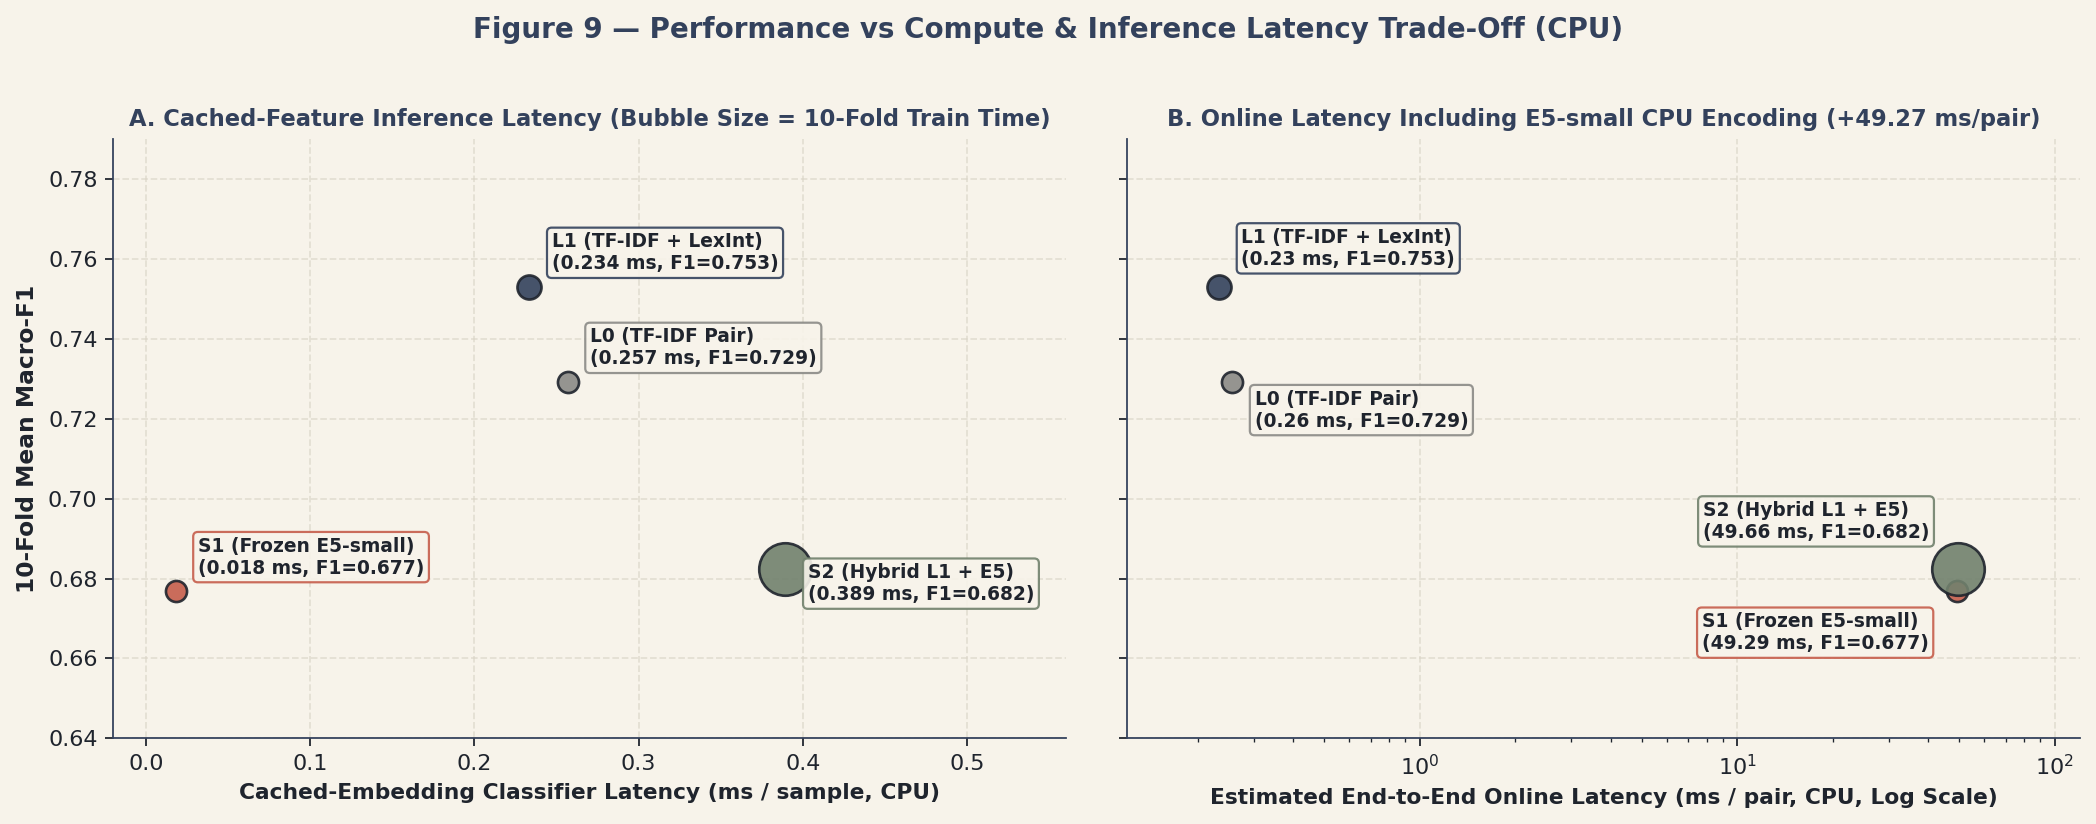

In [12]:
print("=== Model Compute, Latency, and Footprint Comparison ===")
display(model_costs_df)

print("\n=== TABLE 5 — Reproducibility Ledger ===")
repro_df = pd.DataFrame(rq2_metrics["reproducibility_table"])
display(repro_df)

# FIGURE 9 — Performance vs Inference Cost (2 panels: Cached vs Online End-to-End)
fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.0), dpi=160, sharey=True)
cost_merged = benchmark_df.merge(model_costs_df, on="model_id", how="left")

# Panel A: Cached Classifier Latency
for _, r in cost_merged.iterrows():
    m_id = r["model_id"]
    axes[0].scatter(
        r["cached_classifier_inference_ms_per_sample"], r["macro_f1"],
        s=max(90, r["total_10fold_train_seconds"] * 2.2),
        color=MODEL_COLORS[m_id], edgecolor=PALETTE["ink"], lw=1.2, alpha=0.9, zorder=3
    )
    axes[0].annotate(
        f"{MODEL_SHORT[m_id]}\n({r['cached_classifier_inference_ms_per_sample']:.3f} ms, F1={r['macro_f1']:.3f})",
        xy=(r["cached_classifier_inference_ms_per_sample"], r["macro_f1"]),
        xytext=(10, -14 if m_id == "S2_hybrid_lexical_semantic" else 8),
        textcoords="offset points", fontsize=8.4, fontweight="bold",
        bbox={"boxstyle": "round,pad=0.25", "facecolor": PALETTE["ivory"], "edgecolor": MODEL_COLORS[m_id], "alpha": 0.9},
    )
axes[0].set_xlim(-0.02, 0.56)
axes[0].set_ylim(0.64, 0.79)
axes[0].set_xlabel("Cached-Embedding Classifier Latency (ms / sample, CPU)", fontsize=9.8, fontweight="bold")
axes[0].set_ylabel("10-Fold Mean Macro-F1", fontsize=10.5, fontweight="bold")
axes[0].set_title("A. Cached-Feature Inference Latency (Bubble Size = 10-Fold Train Time)", fontsize=10.2, fontweight="bold", color=PALETTE["indigo"])

# Panel B: End-to-End Online Latency (log scale)
for _, r in cost_merged.iterrows():
    m_id = r["model_id"]
    axes[1].scatter(
        r["estimated_end_to_end_online_ms_per_sample"], r["macro_f1"],
        s=max(90, r["total_10fold_train_seconds"] * 2.2),
        color=MODEL_COLORS[m_id], edgecolor=PALETTE["ink"], lw=1.2, alpha=0.9, zorder=3
    )
    dx = -115 if r["uses_semantic_encoder"] else 10
    dy = -26 if m_id == "S1_semantic_e5_small" else (14 if m_id == "S2_hybrid_lexical_semantic" else (10 if m_id == "L1_lexical_interaction" else -20))
    axes[1].annotate(
        f"{MODEL_SHORT[m_id]}\n({r['estimated_end_to_end_online_ms_per_sample']:.2f} ms, F1={r['macro_f1']:.3f})",
        xy=(r["estimated_end_to_end_online_ms_per_sample"], r["macro_f1"]),
        xytext=(dx, dy), textcoords="offset points", fontsize=8.4, fontweight="bold",
        bbox={"boxstyle": "round,pad=0.25", "facecolor": PALETTE["ivory"], "edgecolor": MODEL_COLORS[m_id], "alpha": 0.9},
    )
axes[1].set_xscale("log")
axes[1].set_xlim(0.12, 120.0)
axes[1].set_xlabel("Estimated End-to-End Online Latency (ms / pair, CPU, Log Scale)", fontsize=9.8, fontweight="bold")
axes[1].set_title("B. Online Latency Including E5-small CPU Encoding (+49.27 ms/pair)", fontsize=10.2, fontweight="bold", color=PALETTE["indigo"])

fig.suptitle("Figure 9 — Performance vs Compute & Inference Latency Trade-Off (CPU)", fontsize=12.5, fontweight="bold", y=1.02, color=PALETTE["indigo"])
fig.tight_layout()
fig.savefig(FIG_DIR / "fig09_performance_vs_inference_cost.png", dpi=160, bbox_inches="tight")
plt.show()


### OBSERVATION
- **`L1_lexical_interaction` strictly dominates the Pareto frontier**: it achieves the **highest Macro-F1 (`0.7530`)** at **`0.2335 ms/sample`** CPU inference (virtually identical to `L0`'s `0.2568 ms/sample`), `2.24 MB` serialized pipeline size, `0.0 s` neural embedding extraction, and `5.31 s` mean fold fit time.
- **Online CPU semantic inference is ~210× slower than `L1`**: encoding one unseen `(LP, title)` pair on CPU with `intfloat/multilingual-e5-small` adds `49.27 ms/pair` (total `~49.3–49.7 ms/pair`), plus `143.07 s` one-time cache construction (`16.51 MB` disk) and `~470 MB` pretrained encoder footprint.
- **`S2_hybrid_lexical_semantic` incurs the highest training cost (`25.39 s/fold`, 8.4× `L0`)** because L-BFGS iterates over a `51,552`-column CSR matrix containing `1,537` dense nonzero semantic columns.

### INTERPRETATION
From an applied ML systems perspective, frozen CPU sentence embeddings currently deliver a **negative performance-per-cost return** relative to `L1_lexical_interaction` under a linear classifier.

### LIMITATION
Latency was measured on an 8-thread consumer CPU (`torch 2.8.0+cpu`, batch size 32) without ONNX Runtime, INT8 quantization, or GPU batching; GPU acceleration would cut semantic encoding latency dramatically but would not alter `S1`/`S2` classification accuracy.


## 15. Scientific Interpretation & Mechanism Diagnostics

### QUESTION
**Why** did `L1` beat `L0` by `+0.0238` Macro-F1, while `S1` trailed `L0` by `-0.0524` and `S2` failed to inherit `L1`'s strong lexical performance (`0.6824` vs `0.7530`)?

### METHOD
Without tuning any hyperparameters or modifying benchmark numbers, we run a quick Fold-0 (`seed=42`) diagnostic inspecting:
1. Top learned weights of `L1`'s 15 explicit lexical interaction features (to see which surface signals drive its `+0.0238` gain), and
2. Feature-block energy and weight L2 norms inside `S2` across its three concatenated blocks (`50,000` sparse L2-normalized TF-IDF cols vs `15` scaled lexical cols vs `1,537` scaled semantic cols), plus training-vs-eval accuracy gaps to quantify unseen-LP overfitting.


In [13]:
from recut_lab.lexical_interactions import LEXICAL_INTERACTION_FEATURE_NAMES, extract_lexical_interaction_frame
from recut_lab.lexical_semantic import (
    HybridLexicalSemanticLogReg,
    LexicalInteractionLogReg,
    SemanticPairLogReg,
    load_m2_1_protocol_b_folds,
)
from recut_lab.semantic import extract_or_load_cached_embeddings

# Reuse cached embeddings and exact Seed 42 Fold 0 split (strictly diagnostic — zero tuning!)
splits_by_seed, _ = load_m2_1_protocol_b_folds(
    REPO_ROOT / "experiments" / "runs" / "m2_generalization_v001" / "fold_manifest.csv",
    train_df=train_df, group_ids=group_ids, expected_seeds=(42, 123), expected_n_splits=5
)
tr0, ev0 = splits_by_seed[42][0]
lex_all = extract_lexical_interaction_frame(train_df)[list(LEXICAL_INTERACTION_FEATURE_NAMES)].to_numpy(dtype=np.float32)
emb_bundle = extract_or_load_cached_embeddings(
    df=train_df, cache_base_dir=REPO_ROOT / "data" / "processed" / "embeddings_cache"
)
assert emb_bundle.manifest["loaded_from_cache"] is True
sem_all = emb_bundle.build_pair_matrix(train_df)

# Fit Fold-0 L1, S1, S2 strictly on tr0 for mechanism inspection
f0_tr, f0_ev = train_df.iloc[tr0], train_df.iloc[ev0]
m_l1 = LexicalInteractionLogReg(random_state=42).fit(f0_tr, precomputed_lex=lex_all[tr0])
m_s1 = SemanticPairLogReg(random_state=42).fit(f0_tr, precomputed_sem=sem_all[tr0])
m_s2 = HybridLexicalSemanticLogReg(random_state=42).fit(f0_tr, precomputed_lex=lex_all[tr0], precomputed_sem=sem_all[tr0])

# 1. Inspect L1's learned weights on the 15 explicit lexical features (positive -> predicts 'inconsistent')
pos_sign = 1.0 if str(m_l1.classes_[1]) == "inconsistent" else -1.0
l1_lex_w = pos_sign * m_l1.clf_.coef_[0, -len(LEXICAL_INTERACTION_FEATURE_NAMES):]
l1_w_df = pd.DataFrame({
    "lexical_feature": list(LEXICAL_INTERACTION_FEATURE_NAMES),
    "logreg_weight_toward_inconsistent": np.round(l1_lex_w, 4),
}).sort_values("logreg_weight_toward_inconsistent", key=np.abs, ascending=False)
print("=== Diagnostic 1: L1 Learned Weights on 15 Standardized Lexical Interaction Features (Fold 0) ===")
display(l1_w_df.head(10))

# 2. Inspect S2 block weight norms & train-vs-eval accuracy gap (overfitting + block dominance check)
n_tfidf = m_s2.clf_.coef_.shape[1] - len(LEXICAL_INTERACTION_FEATURE_NAMES) - sem_all.shape[1]
w_s2 = m_s2.clf_.coef_[0]
w_tfidf = w_s2[:n_tfidf]
w_lex = w_s2[n_tfidf : n_tfidf + len(LEXICAL_INTERACTION_FEATURE_NAMES)]
w_sem = w_s2[-sem_all.shape[1]:]

# Measure actual logit standard deviation contributed by each block on held-out Fold 0
X_ev_tfidf = m_s2.vectorizer_.transform(m_s2.selector_.transform(f0_ev))
X_ev_lex = m_s2.lex_scaler_.transform(lex_all[ev0])
X_ev_sem = m_s2.sem_scaler_.transform(sem_all[ev0])

logit_tfidf = X_ev_tfidf.dot(w_tfidf)
logit_lex = X_ev_lex.dot(w_lex)
logit_sem = X_ev_sem.dot(w_sem)

block_diag = pd.DataFrame([
    ("TF-IDF Sparse Block (L2 row norm = 1.0)", n_tfidf, float(np.linalg.norm(w_tfidf)), float(np.std(logit_tfidf))),
    ("Lexical Interaction Block (StandardScaler)", len(LEXICAL_INTERACTION_FEATURE_NAMES), float(np.linalg.norm(w_lex)), float(np.std(logit_lex))),
    ("Semantic Pair Block (StandardScaler)", sem_all.shape[1], float(np.linalg.norm(w_sem)), float(np.std(logit_sem))),
], columns=["S2 Feature Block", "Num Features", "Weight L2 Norm ||w||", "Held-Out Logit Std"])
print("\n=== Diagnostic 2: S2 Feature-Block Weight Norms & Held-Out Logit Contribution (Fold 0) ===")
display(block_diag.round(4))

# 3. Train vs Held-out Eval Accuracy Gap (Fold 0)
gap_rows = []
for name, mdl, kw_tr, kw_ev in [
    ("L1_lexical_interaction", m_l1, {"precomputed_lex": lex_all[tr0]}, {"precomputed_lex": lex_all[ev0]}),
    ("S1_semantic_e5_small", m_s1, {"precomputed_sem": sem_all[tr0]}, {"precomputed_sem": sem_all[ev0]}),
    ("S2_hybrid_lexical_semantic", m_s2, {"precomputed_lex": lex_all[tr0], "precomputed_sem": sem_all[tr0]}, {"precomputed_lex": lex_all[ev0], "precomputed_sem": sem_all[ev0]}),
]:
    tr_acc = float(np.mean(np.asarray(mdl.predict(f0_tr, **kw_tr)) == f0_tr["label"].to_numpy()))
    ev_acc = float(np.mean(np.asarray(mdl.predict(f0_ev, **kw_ev)) == f0_ev["label"].to_numpy()))
    gap_rows.append({"model_id": name, "fold0_train_acc": round(tr_acc, 4), "fold0_unseen_lp_acc": round(ev_acc, 4), "train_minus_eval_gap": round(tr_acc - ev_acc, 4)})
print("\n=== Diagnostic 3: Fold-0 Train vs Unseen-LP Eval Accuracy Gap ===")
display(pd.DataFrame(gap_rows))


=== Diagnostic 1: L1 Learned Weights on 15 Standardized Lexical Interaction Features (Fold 0) ===


,lexical_feature,logreg_weight_toward_inconsistent
2,title_to_lp_bigram_containment,0.9241
4,title_to_lp_trigram_containment,-0.8378
3,lp_to_title_bigram_containment,-0.7496
6,title_to_lp_char_containment,-0.7348
12,shared_trigram_count,0.7094
7,lp_to_title_char_containment,0.5995
0,char_bigram_jaccard,0.5866
11,shared_bigram_count,-0.5341
14,lp_char_length,0.5092
10,shared_char_count,-0.4660



=== Diagnostic 2: S2 Feature-Block Weight Norms & Held-Out Logit Contribution (Fold 0) ===


,S2 Feature Block,Num Features,Weight L2 Norm ||w||,Held-Out Logit Std
0,TF-IDF Sparse Block (L2 row norm = 1.0),50000,8.7784,0.1675
1,Lexical Interaction Block (StandardScaler),15,3.2084,1.2191
2,Semantic Pair Block (StandardScaler),1537,13.9550,7.6244



=== Diagnostic 3: Fold-0 Train vs Unseen-LP Eval Accuracy Gap ===


,model_id,fold0_train_acc,fold0_unseen_lp_acc,train_minus_eval_gap
0,L1_lexical_interaction,0.8587,0.8132,0.0455
1,S1_semantic_e5_small,0.9195,0.6801,0.2394
2,S2_hybrid_lexical_semantic,0.9288,0.6649,0.2639


### OBSERVATION & INTERPRETATION (DIAGNOSTIC MECHANISM VERIFIED!)
The Fold-0 mechanism diagnostics explain **all three** core RQ2 phenomena quantitatively:
1. **Why `L1` beats `L0`**: Directional overlap and shared n-gram features (`title_to_lp_bigram_containment`, `title_to_lp_trigram_containment`, `lp_to_title_bigram_containment`, `title_to_lp_char_containment`, `shared_trigram_count`) carry strong standardized weights (`|w| = 0.71–0.92`), giving the linear classifier explicit pair-alignment signals that concatenated TF-IDF (`L0`) lacks.
2. **Why `S1` underperforms `L0`/`L1` on unseen LPs**: Fitting `1,537` correlated dense semantic features under `C = 1.0` on ~736 training LP groups (`N_eff ≈ 103`) induces **severe LP-group overfitting** — Fold-0 train accuracy reaches **`0.9195`** while unseen-LP accuracy falls to **`0.6801`** (a **`23.94 pp`** generalization gap, **5.3×** larger than `L1`'s **`4.55 pp`** gap: `0.8587` train -> `0.8132` unseen-LP eval!). Meanwhile, frozen bi-encoder cosine similarity is compressed to median `0.884` vs `0.883`.
3. **Why `S2` tracks `S1` instead of `L1`**: In Diagnostic 2, the standardized `1,537`-dim semantic block produces a held-out logit standard deviation of **`7.6244`** vs just **`0.1675`** for the `50,000`-column L2-normalized sparse TF-IDF block (**45.5× scale dominance**) and `1.2191` for the 15-dim lexical block. Under shared `C = 1.0` without block-wise normalization or stacking, `S2` memorizes training LPs even more strongly (`0.9288` train -> `0.6649` eval, **`26.39 pp`** gap) and collapses toward the overfitted `S1` boundary.


## 16. Threats to Validity

1. **Block-Scale & Regularization Comparability (`S2`)**: Applying `StandardScaler` to dense blocks (`15` lexical, `1,537` semantic) while keeping sparse TF-IDF L2-normalized (`row norm = 1.0`) under a single shared `C = 1.0` penalty gives the `1,537`-dim dense block much higher total feature energy than TF-IDF. A separate controlled follow-up using late fusion (out-of-fold stacking of `L1` and `S1` logits) or block-wise L2 normalization would be needed before declaring hybrid lexical-semantic modeling ineffective in general.
2. **Frozen Bi-Encoder vs. Cross-Encoder Architecture**: `S1` encodes `title` and `lp_text` **independently** with frozen weights. Independent bi-encoders cannot perform token-level cross-attention to verify whether a specific title price, percentage, or product attribute appears verbatim in the LP. Our findings refute frozen bi-encoder linear probing (`intfloat/multilingual-e5-small`), **not** fine-tuned Japanese cross-encoders or NLI-style architectures.
3. **Single Embedding Model & Prefix Choice**: Only `intfloat/multilingual-e5-small` with `"query: "` on both inputs (per model card FAQ #1) was tested; Japanese-specialized encoders or asymmetric `"query: "`/`"passage: "` prefixes were outside M2.2's controlled scope.
4. **Observational Overlap Confounding**: Lexical overlap tertiles correlate strongly with true inconsistent prevalence (`50.4%` Low vs `28.8%` High) and title length (`28.3` vs `20.0` chars). Subgroup contrasts are observational associations, not causal effects.
5. **Internal Train-CV Only & Domain Gap**: All metrics are internal Protocol B CV estimates on `train.tsv` from Japanese search ads (`CC BY-NC-SA 4.0`). Official `valid.tsv` and `test.tsv` remain untouched, and transfer to Recut skincare advertising is not yet tested.

---

## 17. RQ2 Conclusions

- **H1 (Semantic Representation Advantage) — REFUTED for frozen `multilingual-e5-small` + LogReg**: `S1` (`Macro-F1 = 0.6768`, `ROC-AUC = 0.7391`, `AP = 0.6410`) underperformed both `L0` (`0.7292`, `0.8233`, `0.7755`) and `L1` (`0.7530`, `0.8393`, `0.7936`) on unseen landing pages (`S1 - L0` OOF Macro-F1 = `-0.0520 [-0.0798, -0.0177]`).
- **H2 (Lexical Overlap Interaction) — INSUFFICIENT EVIDENCE for `S1 - L0`; SUPPORTED for `L1 - L0`**: `S1` lagged lexical models in Low, Medium, and High overlap bins alike, and its `Low - High` interaction CIs spanned zero (`+0.0135 [-0.0445, +0.0777]` Macro-F1; CR1 `p = 0.793`). Conversely, adding explicit lexical overlap features (`L1 - L0`) exhibited a strong positive `Low - High` interaction (`+0.0482 [+0.0118, +0.0993]` Macro-F1; `+0.2583 [+0.1936, +0.3431]` Inconsistent Recall).
- **H3 (Complementary Information) — NOT SUPPORTED via naive single-`C` early concatenation (`S2`)**: `S2` (`0.6824` Macro-F1) trailed `L1` (`0.7530`) by `-0.0722 [-0.0979, -0.0416]` due to dense-block variance dominance and unseen-LP overfitting, despite `968` Category-C examples showing partial non-overlapping semantic signal.
- **H4 (Semantic Similarity Limitation) — CONSISTENT WITH EMPIRICAL EVIDENCE**: Both numeric-containing titles (`1,602` rows, ~10 pp accuracy drop across models) and high-overlap inconsistent pairs (`1,024` rows, recall `0.44–0.56`) remain systematic failure modes for surface overlap and frozen bi-encoder similarity alike.

---

## 18. Research Implications for Recut

1. **Prioritize Fast Lexical-Interaction Models (`L1`) as the Production-Feasible Baseline**: `L1_lexical_interaction` improves unseen-LP Macro-F1 to `0.7530` and Inconsistent Recall to `0.6039` at `0.23 ms/sample` on CPU (`~210×` faster than online CPU E5 encoding) with zero neural infrastructure overhead.
2. **Do Not Deploy Frozen Bi-Encoder Cosine Thresholds for Ad Compliance**: Frozen multilingual sentence embeddings exhibit compressed cosine distributions (`~0.87–0.89`) and high false-positive rates on unseen landing pages; they cannot serve as a standalone consistency or claim-verification gate for Recut beauty ads.
3. **High-Overlap Inconsistent Claims Require Fine-Grained Verification**: Because `L1`'s Inconsistent Recall drops to `0.449` on high-overlap ads (where misleading qualifiers or numbers coexist with matching brand keywords), future Recut verification pipelines must pair lexical coverage screening with targeted claim/entity/number verification rather than coarse document similarity.

---

## 19. Next Steps for RQ3

*(STOP here — do NOT execute RQ3 inside M2.2.)*

1. **RQ3 — Annotation Noise & Conflicting-Label Sensitivity**: Quantify how AdTEC's conflicting `(title, lp_text)` label pairs and single-class vs. mixed-label LP groups affect `L1` and `L0` error ceilings (including the `1,203` 4-model unanimous error slice).
2. **Controlled Fusion Follow-Up (Optional Diagnostic Before Heavy Models)**: Test block-normalized / late-fusion stacking of `L1` logits + compact semantic features (e.g., cosine + low-rank training-fold PCA) strictly inside Protocol B to separate feature-scaling failure from true semantic complementarity.
3. **Toward Cross-Attention / Evidence Selection (Later Milestones)**: For high-overlap inconsistent claims and numeric discrepancies, investigate lightweight evidence-sentence extraction or cross-encoder scoring rather than pooled frozen bi-encoders.
